<div style="background: linear-gradient(135deg, #0f766e, #1e3a8a); color: white; padding: 30px; border-radius: 12px;">
<h1 style="color:white; margin-bottom:4px;">Análisis exploratorio avanzado con Matplotlib y Seaborn</h1>
<h3 style="color:#d1fae5; margin-top:0;">Caso de estudio: dataset <i>Auto MPG</i></h3>
<p style="color:#d1fae5;">Grupo 4 · Karen Johanna García Martínez · Juan Camilo Diaz Gamboa · Christian David Diaz Bustamante  · 16/10/2026</p>
</div>

## Contenido

| Bloque | Temas |
|---|---|
| **Preparación** | Librerías, carga del dataset Auto MPG y repaso del diagnóstico inicial. |
| **Parte 1. EDA y relaciones numéricas** | EDA inicial y avanzado, relaciones entre variables, diagramas de dispersión con Matplotlib y `scatterplot` con Seaborn. Análisis de peso, potencia, cilindrada y MPG. |
| **Parte 2. Correlaciones y variables categóricas** | Correlación, matriz de correlaciones, heatmap, detección de correlaciones fuertes, tablas cruzadas con `crosstab`, frecuencias y porcentajes. |
| **Parte 3. Atípicos y hallazgos** | Tablas cruzadas, valores atípicos, boxplot, regla del IQR, comparación entre grupos, `barplot`, `pairplot` y documentación de hallazgos. |
| **Cierre** | Respuestas a las preguntas de análisis y conclusiones finales. |

**Objetivo:** analizar el dataset Auto MPG para comprender cómo se relacionan las características de los vehículos con su consumo de combustible, identificar valores atípicos y comparar resultados según el origen.

**Preguntas clave:**
- ¿Cómo se relacionan el peso y el MPG?
- ¿Qué variables tienen mayor correlación con el MPG?
- ¿Existen valores atípicos?
- ¿Hay diferencias según el origen de los vehículos?

**Cómo usar el notebook:**
1. Ejecuta las celdas en orden con `Shift + Enter`.
2. Si falla la descarga, carga manualmente el archivo `auto-mpg.csv`.
3. Revisa las gráficas y sus interpretaciones.
4. Finaliza con **tres hallazgos respaldados por los resultados**.



## 0. Preparación

### 0.1 Librerías y configuración

- **pandas / numpy** → manipulación de datos y cálculos.
- **matplotlib** → gráficas construidas pieza por pieza.
- **seaborn** → gráficas estadísticas directamente desde el DataFrame.

Definimos también **colores fijos por origen**: el mismo color significará lo mismo en todas las gráficas.

In [ ]:
# 0.1 LIBRERÍAS Y CONFIGURACIÓN
import numpy as np # Operaciones numéricas y cálculos matemáticos
import pandas as pd # Organizar y manipular datos en tablas
import matplotlib.pyplot as plt # Construir gráficas y personalizar sus elementos
import seaborn as sns # Creación de gráficas estadísticas


# Estilo visual para todas las gráficas
sns.set_theme(style="whitegrid", font_scale=1.05)
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titleweight"] = "bold"
pd.set_option("display.max_columns", 50)

# Colores fijos por origen
ORDEN_ORIGEN = ["USA", "Europa", "Japón"]
PALETA_ORIGEN = {"USA": "#2E86AB", "Europa": "#F18F01", "Japón": "#C73E1D"}
#USA Azul #2E86AB · Europa Naranja #F18F01 · Japón Rojo oscuro #C73E1D


# Variables numéricas y nombres en español para los ejes
NUMERICAS = ["mpg", "cylinders", "displacement", "horsepower", "weight", "acceleration", "model_year"]
ETIQUETAS = {
    "mpg": "Rendimiento (mpg)",
    "cylinders": "Cilindros",
    "displacement": "Cilindrada (pulg³)",
    "horsepower": "Potencia (hp)",
    "weight": "Peso (lb)",
    "acceleration": "Aceleración 0–60 mph (s)",
    "model_year": "Año del modelo",
}

print("LIBRERÍAS CARGADAS")

LIBRERÍAS CARGADAS


### 0.2 Carga del dataset

**Auto MPG** (UCI Machine Learning Repository) tiene **398 carros** de **1970 a 1982**. Es el mismo dataset que usó el grupo 3, así que solo repetimos la **limpieza mínima**:

- `na_values="?"` → el `?` de `horsepower` es un faltante.
- Nombres de columnas sin espacios (`model year` → `model_year`).
- `origin` (1, 2, 3) → `origen` con nombre legible (USA, Europa, Japón).

| Variable | Descripción | Unidad |
|---|---|---|
| `mpg` | Millas por galón (**rendimiento**: más mpg = gasta menos) | mi/gal |
| `cylinders` | Número de cilindros | — |
| `displacement` | Cilindrada del motor | pulg³ |
| `horsepower` | Potencia | hp |
| `weight` | Peso | lb |
| `acceleration` | Tiempo de 0 a 60 mph | s |
| `model_year` | Año del modelo (70 = 1970) | año |
| `origin` | 1 = USA, 2 = Europa, 3 = Japón | código |
| `car_name` | Nombre del carro | texto |

In [ ]:
# 0.2 CARGA DEL DATASET
try:
    import kagglehub                                   # descarga directa desde Kaggle
    carpeta = kagglehub.dataset_download("uciml/autompg-dataset")
    RUTA = f"{carpeta}/auto-mpg.csv"
except Exception:
    from google.colab import files                     # respaldo: subir el CSV a mano
    print("No se pudo descargar desde Kaggle. Selecciona auto-mpg.csv:")
    subido = files.upload()
    RUTA = list(subido.keys())[0]

# "?" es el código de faltante de este dataset
df = pd.read_csv(RUTA, na_values="?")

# Limpieza mínima: nombres sin espacios y origen con nombre legible
df.columns = df.columns.str.strip().str.replace(" ", "_")
df["origen"] = pd.Categorical(df["origin"].map({1: "USA", 2: "Europa", 3: "Japón"}),
                              categories=ORDEN_ORIGEN)

print("ARCHIVO:", RUTA)
print(f"DIMENSIONES: {df.shape[0]} filas × {df.shape[1]} columnas")
df.head()

100%|██████████| 6.31k/6.31k [00:00<00:00, 8.69MB/s]

Extracting files...
ARCHIVO: /root/.cache/kagglehub/datasets/uciml/autompg-dataset/versions/3/auto-mpg.csv
DIMENSIONES: 398 filas × 10 columnas


,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year,origin,car_name,origen
0,18.0,8,307.0,130.0,3504,12.0,70,1,chevrolet chevelle malibu,USA
1,15.0,8,350.0,165.0,3693,11.5,70,1,buick skylark 320,USA
2,18.0,8,318.0,150.0,3436,11.0,70,1,plymouth satellite,USA
3,16.0,8,304.0,150.0,3433,12.0,70,1,amc rebel sst,USA
4,17.0,8,302.0,140.0,3449,10.5,70,1,ford torino,USA


### 0.3 Repaso rápido del diagnóstico

In [ ]:
# 0.3 REPASO RÁPIDO DEL DIAGNÓSTICO
diagnostico = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "faltantes": df.isna().sum(),
    "valores_unicos": df.nunique(),
})
print("FILAS DUPLICADAS:", df.duplicated().sum())
diagnostico

FILAS DUPLICADAS: 0


,tipo,faltantes,valores_unicos
mpg,float64,0,129
cylinders,int64,0,5
displacement,float64,0,82
horsepower,float64,6,93
weight,int64,0,351
acceleration,float64,0,95
model_year,int64,0,13
origin,int64,0,3
car_name,object,0,305
origen,category,0,3


- Solo `horsepower` tiene faltantes (**6 carros**) y no hay duplicados.
- **Decisión:** en el EDA **no imputamos** esos 6 valores. Si los rellenáramos con la media, inventaríamos 6 puntos justo en el centro de las gráficas y suavizaríamos las relaciones. pandas y seaborn **omiten los `NaN` automáticamente** en cada cálculo.

<div style="background:#0f766e; color:white; padding:18px; border-radius:10px;">
<h1 style="color:white; margin:0;">PARTE 1 — EDA y relaciones numéricas</h1>
<p style="color:#d1fae5; margin:6px 0 0 0;">EDA inicial vs avanzado · Relaciones numéricas · Dispersión con Matplotlib y Seaborn · Aplicación</p>
</div>

## 1. Diferencia entre EDA inicial y EDA avanzado

| | **EDA inicial** (lo que hizo el grupo 3) | **EDA avanzado** (lo que hacemos hoy) |
|---|---|---|
| **Pregunta** | ¿Cómo es cada variable? | ¿Cómo se relacionan las variables entre sí? |
| **Variables a la vez** | Una (análisis *univariado*) | Dos o más (*bivariado* y *multivariado*) |
| **Herramientas** | `describe()`, `value_counts()`, histograma, boxplot simple | Dispersión, correlación, heatmap, `crosstab`, boxplot por grupos, `pairplot` |
| **Resultado** | Conocer los datos y detectar problemas | Encontrar relaciones, grupos y atípicos → **hallazgos** |

**Ejemplo:** el EDA inicial nos dice *cuánto vale* el rendimiento promedio. El EDA avanzado pregunta **¿de qué depende?**

In [ ]:
# 1.1 EDA INICIAL VS EDA AVANZADO
print("EDA INICIAL: CADA VARIABLE POR SEPARADO")
display(df[["mpg", "weight"]].describe().T.round(1))

print("EDA AVANZADO: DOS VARIABLES A LA VEZ (MPG SEGÚN EL RANGO DE PESO)")
rango_peso = pd.cut(df["weight"], bins=[1500, 2500, 3500, 5200],
                    labels=["Menos de 2500 lb", "2500–3500 lb", "Más de 3500 lb"])
display(df.groupby(rango_peso, observed=True)["mpg"].agg(carros="count", mpg_promedio="mean").round(1))

EDA INICIAL: CADA VARIABLE POR SEPARADO


,count,mean,std,min,25%,50%,75%,max
mpg,398.0,23.5,7.8,9.0,17.5,23.0,29.0,46.6
weight,398.0,2970.4,846.8,1613.0,2223.8,2803.5,3608.0,5140.0


EDA AVANZADO: DOS VARIABLES A LA VEZ (MPG SEGÚN EL RANGO DE PESO)


,carros,mpg_promedio
weight,,
Menos de 2500 lb,147,30.6
2500–3500 lb,142,22.5
Más de 3500 lb,109,15.2


**Interpretación:**

- `describe()` dice que el rendimiento promedio es de **≈ 23.5 mpg**, pero no explica **por qué** unos carros rinden más que otros.
- Al cruzar con el peso aparece la historia: los carros de menos de 2500 lb rinden **≈ 30.6 mpg** y los de más de 3500 lb solo **≈ 15.2 mpg**, es decir, **la mitad**.
- Esa es la idea del EDA avanzado: **mirar variables juntas** para encontrar relaciones.

## 2. Relaciones entre variables numéricas

Cuando miramos dos variables numéricas describimos **tres cosas**:

| Característica | Pregunta | Posibles respuestas |
|---|---|---|
| **Dirección** | Cuando una sube, ¿la otra sube o baja? | Positiva / negativa |
| **Forma** | ¿Los puntos siguen una recta o una curva? | Lineal / no lineal |
| **Fuerza** | ¿Los puntos están juntos o muy dispersos? | Fuerte / débil |

Y también puede pasar que **no haya relación**. La siguiente imagen muestra los casos típicos con datos simulados:

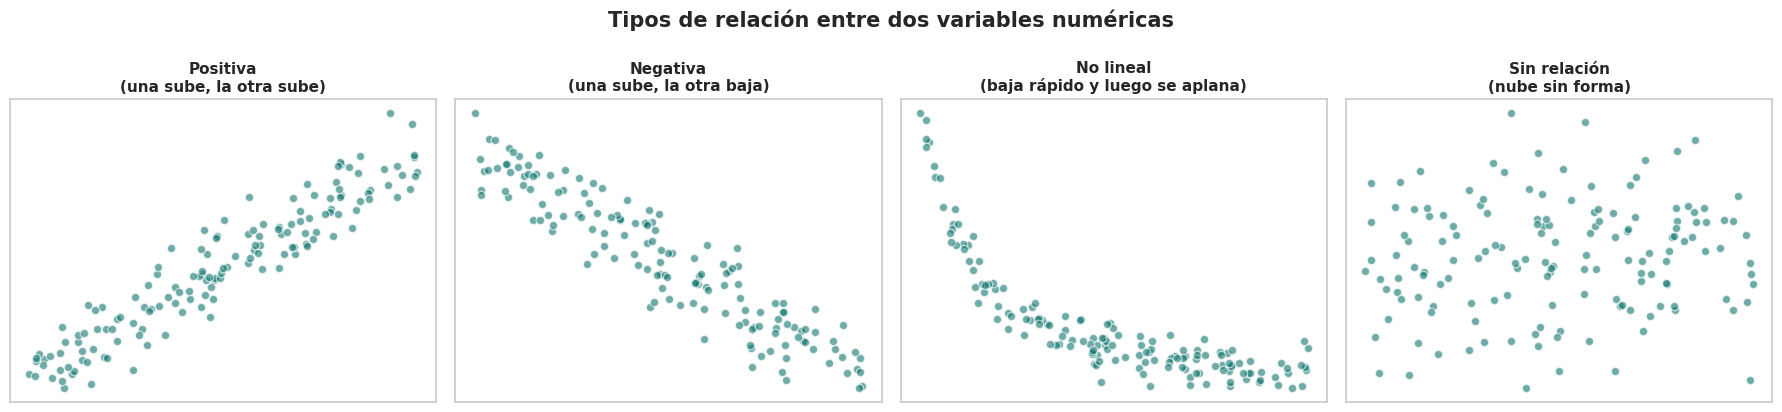

In [ ]:
# 2.1 IMAGEN: TIPOS DE RELACIÓN ENTRE DOS VARIABLES (DATOS SIMULADOS)
rng = np.random.default_rng(42)
x = rng.uniform(0, 10, 150)
ejemplos = {
    "Positiva\n(una sube, la otra sube)": 2 * x + rng.normal(0, 2, 150),
    "Negativa\n(una sube, la otra baja)": -2 * x + rng.normal(0, 2, 150),
    "No lineal\n(baja rápido y luego se aplana)": 40 / (x + 1) + rng.normal(0, 1.5, 150),
    "Sin relación\n(nube sin forma)": rng.normal(0, 5, 150),
}

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2))
for ax, (titulo, y) in zip(axes, ejemplos.items()):
    ax.scatter(x, y, alpha=0.6, color="#0f766e", edgecolor="white")
    ax.set_title(titulo, fontsize=11)
    ax.set_xticks([])
    ax.set_yticks([])
plt.suptitle("Tipos de relación entre dos variables numéricas", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

En Auto MPG esperamos ver sobre todo el **segundo y el tercer caso**: relaciones **negativas** (más peso → menos mpg) y con algo de **curva**.

## 3. Diagramas de dispersión con Matplotlib

Un diagrama de dispersión dibuja **un punto por cada carro**: su posición horizontal es una variable y la vertical es otra. Con Matplotlib la gráfica se arma **pieza por pieza**:

```python
fig, ax = plt.subplots()             # lienzo (fig) y área de dibujo (ax)
ax.scatter(x, y, alpha=0.6, s=35)    # los puntos
ax.set_xlabel(...); ax.set_ylabel(...); ax.set_title(...)   # textos
```

| Parámetro | Para qué sirve |
|---|---|
| `alpha` | Transparencia (0 a 1): deja ver los puntos que se superponen |
| `s` | Tamaño de los puntos |
| `color` / `c` | Color fijo, o un color por valor de otra variable |
| `edgecolor` | Borde de cada punto |

El grupo 3 mostró estas gráficas rápidamente con Seaborn. Aquí las construimos desde cero y les agregamos **líneas de tendencia** con `np.polyfit`.

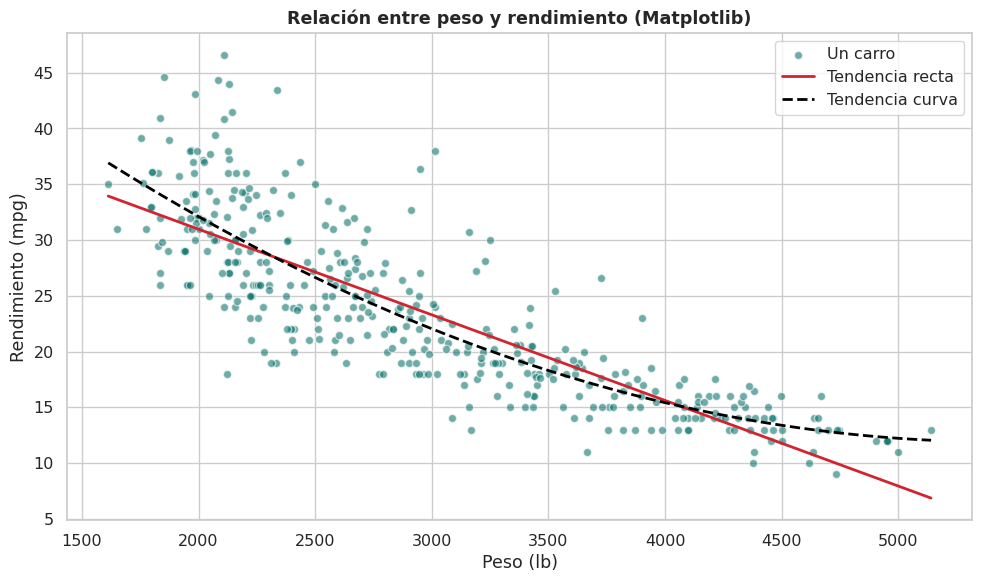

PENDIENTE DE LA RECTA: -0.00768 mpg por libra
→ cada 1000 lb adicionales, el rendimiento baja en promedio 7.7 mpg


In [ ]:
# 3.1 DISPERSIÓN PESO VS MPG CON MATPLOTLIB + LÍNEAS DE TENDENCIA
x = df["weight"]
y = df["mpg"]

pendiente, intercepto = np.polyfit(x, y, deg=1)     # recta:  mpg = a·peso + b
coef_curva = np.polyfit(x, y, deg=2)                # curva:  mpg = a·peso² + b·peso + c
x_linea = np.linspace(x.min(), x.max(), 100)

fig, ax = plt.subplots(figsize=(10, 6))
ax.scatter(x, y, alpha=0.6, s=35, color="#0f766e", edgecolor="white", label="Un carro")
ax.plot(x_linea, pendiente * x_linea + intercepto, color="#d1242f", lw=2, label="Tendencia recta")
ax.plot(x_linea, np.polyval(coef_curva, x_linea), color="black", lw=2, ls="--", label="Tendencia curva")
ax.set_xlabel(ETIQUETAS["weight"])
ax.set_ylabel(ETIQUETAS["mpg"])
ax.set_title("Relación entre peso y rendimiento (Matplotlib)")
ax.legend()
plt.tight_layout()
plt.show()

print(f"PENDIENTE DE LA RECTA: {pendiente:.5f} mpg por libra")
print(f"→ cada 1000 lb adicionales, el rendimiento baja en promedio {abs(pendiente) * 1000:.1f} mpg")

**Interpretación:**

- La relación es **negativa**: a más peso, menos millas por galón.
- Según la recta, **cada 1000 lb adicionales restan ≈ 7.7 mpg**.
- La recta **no describe bien los extremos**: para un carro de 5000 lb predice ≈ 8 mpg, pero los carros reales de ese peso están en 11–13 mpg. La **curva** se ajusta mejor porque la caída **se aplana** en los carros más pesados. Lo retomaremos en la Parte 2 con la correlación de Spearman.

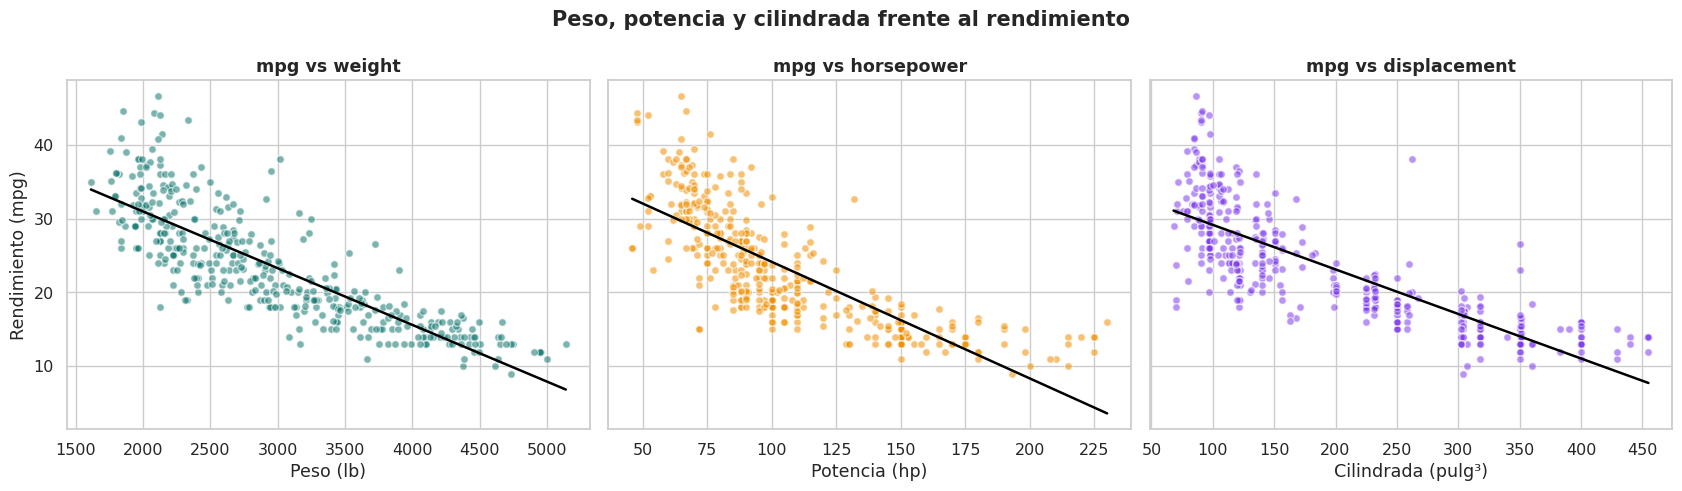

In [ ]:
# 3.2 VARIAS DISPERSIONES EN UNA SOLA FIGURA (SUBPLOTS)
variables = ["weight", "horsepower", "displacement"]
colores = ["#0f766e", "#F18F01", "#7c3aed"]

fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
for ax, var, color in zip(axes, variables, colores):
    datos = df[[var, "mpg"]].dropna()                 # horsepower tiene 6 faltantes
    a, b = np.polyfit(datos[var], datos["mpg"], deg=1)
    x_linea = np.linspace(datos[var].min(), datos[var].max(), 100)
    ax.scatter(datos[var], datos["mpg"], alpha=0.55, s=30, color=color, edgecolor="white")
    ax.plot(x_linea, a * x_linea + b, color="black", lw=1.8)
    ax.set_xlabel(ETIQUETAS[var])
    ax.set_title(f"mpg vs {var}")
axes[0].set_ylabel(ETIQUETAS["mpg"])
plt.suptitle("Peso, potencia y cilindrada frente al rendimiento", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.show()

**Interpretación:** las tres gráficas tienen **la misma forma**: negativa y algo curva. Que se parezcan tanto es una pista de que peso, potencia y cilindrada **miden casi lo mismo** (el "tamaño" del carro). La Parte 2 lo confirma con números.

## 4. `scatterplot` con Seaborn incorporando variables categóricas

Seaborn trabaja **directamente con el DataFrame** (`data=df, x="weight", y="mpg"`) y permite agregar más variables a la misma gráfica:

| Parámetro | Qué cambia | Tipo de variable |
|---|---|---|
| `hue` | Color del punto | Categórica (o numérica) |
| `style` | Forma del marcador | Categórica |
| `size` | Tamaño del punto | Numérica |
| `col` / `row` (en `relplot`) | Una gráfica por grupo | Categórica |

Así, una gráfica de 2 ejes puede mostrar **3 o 4 variables a la vez**.

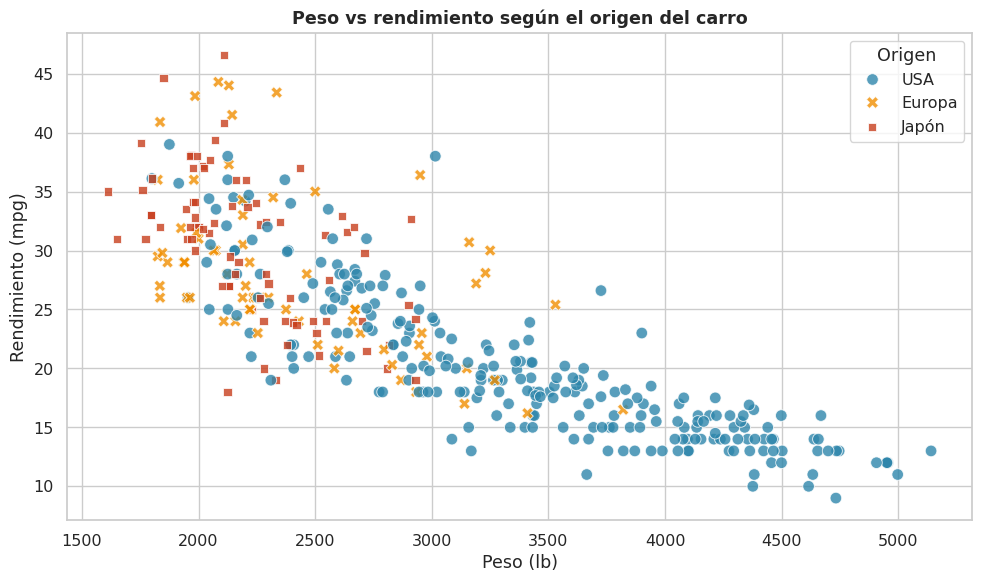

In [ ]:
# 4.1 SCATTERPLOT CON SEABORN: COLOR Y FORMA SEGÚN EL ORIGEN
plt.figure(figsize=(10, 6))
sns.scatterplot(data=df, x="weight", y="mpg",
                hue="origen", style="origen", palette=PALETA_ORIGEN,
                s=70, alpha=0.8)
plt.xlabel(ETIQUETAS["weight"])
plt.ylabel(ETIQUETAS["mpg"])
plt.title("Peso vs rendimiento según el origen del carro")
plt.legend(title="Origen")
plt.tight_layout()
plt.show()

**Interpretación:** los carros de **Japón y Europa** se concentran arriba a la izquierda (livianos y eficientes). **USA** aparece en todo el rango y es prácticamente el único por encima de 3500 lb (**107 de los 109** carros más pesados).

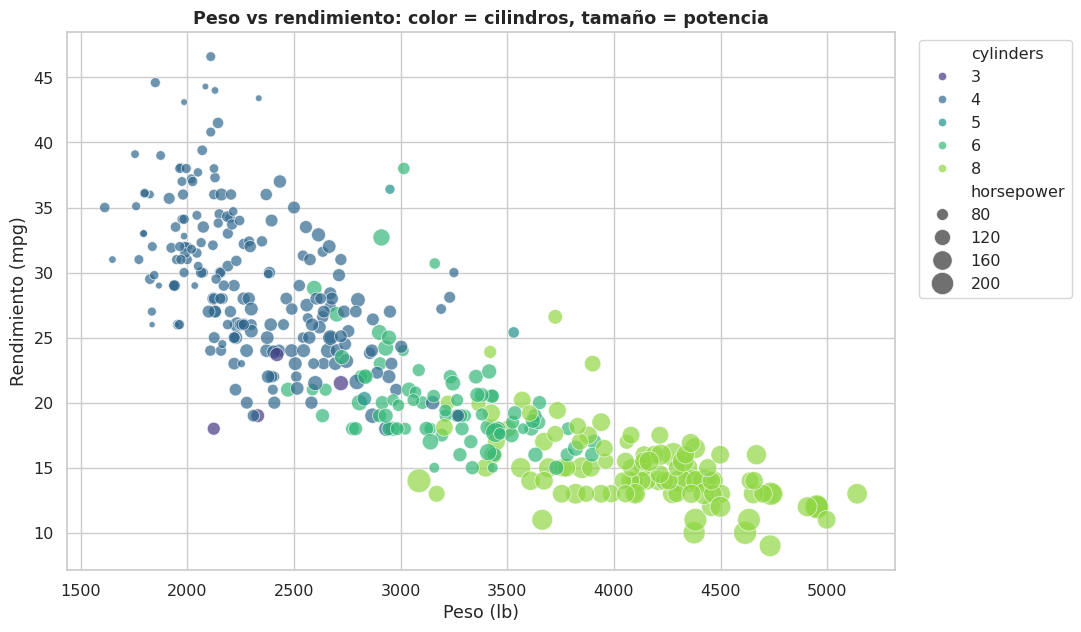

In [ ]:
# 4.2 CUATRO VARIABLES EN UNA GRÁFICA: COLOR = CILINDROS, TAMAÑO = POTENCIA
plt.figure(figsize=(11, 6.5))
sns.scatterplot(data=df, x="weight", y="mpg",
                hue=df["cylinders"].astype(str), hue_order=["3", "4", "5", "6", "8"],
                size="horsepower", sizes=(20, 300),
                palette="viridis", alpha=0.7)
plt.xlabel(ETIQUETAS["weight"])
plt.ylabel(ETIQUETAS["mpg"])
plt.title("Peso vs rendimiento: color = cilindros, tamaño = potencia")
plt.legend(bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Interpretación:** al movernos a la derecha (más peso), el color pasa de **4 a 6 y a 8 cilindros** y los puntos se hacen **más grandes** (más potencia). Peso, cilindros y potencia **se mueven juntos**.

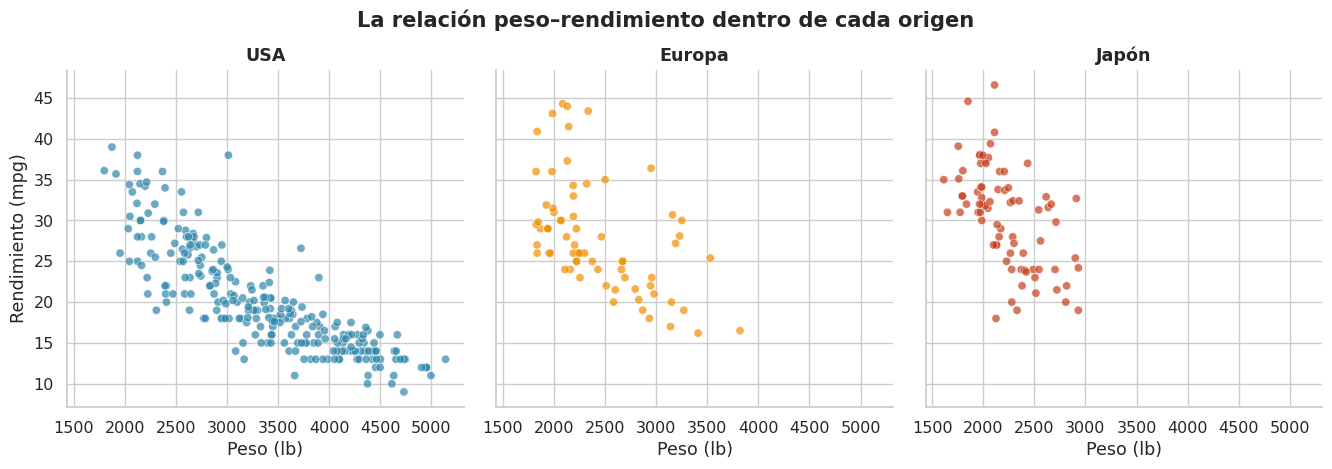

In [ ]:
# 4.3 UNA GRÁFICA POR GRUPO CON relplot (col = origen)
g = sns.relplot(data=df, x="weight", y="mpg", col="origen", hue="origen",
                palette=PALETA_ORIGEN, height=4.5, aspect=1, alpha=0.7, legend=False)
g.set_axis_labels(ETIQUETAS["weight"], ETIQUETAS["mpg"])
g.set_titles("{col_name}")
g.figure.suptitle("La relación peso–rendimiento dentro de cada origen", y=1.04, fontweight="bold")
plt.show()

**Interpretación:**

- Dentro de **cada** origen se repite la misma caída: la relación peso–rendimiento **no depende del origen**, es física (mover más masa cuesta más combustible).
- Japón y Europa casi **no tienen carros pesados**. Pista para la Parte 3: ¿la diferencia entre orígenes se debe en realidad al peso?

## 5. Aplicación: relación entre peso, potencia, cilindrada y MPG

Juntamos lo anterior para responder la primera pregunta del caso. Usamos `sns.regplot` con `order=2`, que dibuja la nube de puntos y una **tendencia curva** en una sola instrucción.

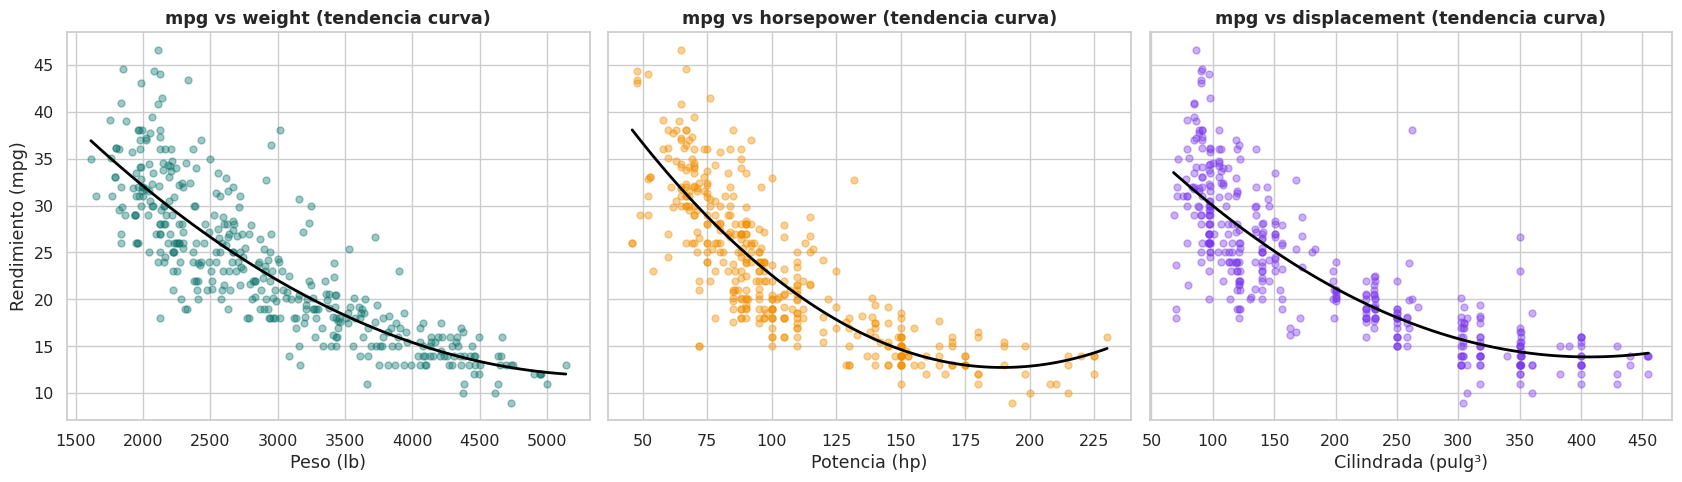

In [ ]:
# 5.1 APLICACIÓN: TENDENCIA CURVA DE MPG CON PESO, POTENCIA Y CILINDRADA
fig, axes = plt.subplots(1, 3, figsize=(17, 5), sharey=True)
for ax, var, color in zip(axes, ["weight", "horsepower", "displacement"], ["#0f766e", "#F18F01", "#7c3aed"]):
    sns.regplot(data=df, x=var, y="mpg", order=2, ci=None, ax=ax,
                scatter_kws={"alpha": 0.4, "s": 25, "color": color},
                line_kws={"color": "black", "lw": 2})
    ax.set_xlabel(ETIQUETAS[var])
    ax.set_ylabel("")
    ax.set_title(f"mpg vs {var} (tendencia curva)")
axes[0].set_ylabel(ETIQUETAS["mpg"])
plt.tight_layout()
plt.show()

In [ ]:
# 5.2 APLICACIÓN: MPG PROMEDIO SEGÚN EL NIVEL DE CADA VARIABLE (CUARTILES)
niveles = ["Q1 (bajo)", "Q2", "Q3", "Q4 (alto)"]
aplicacion = pd.DataFrame({
    ETIQUETAS[var]: df.groupby(pd.qcut(df[var], q=4, labels=niveles), observed=True)["mpg"].mean()
    for var in ["weight", "horsepower", "displacement"]
}).round(1)
aplicacion.index.name = "Nivel de la variable"
print("MPG PROMEDIO EN CADA CUARTIL (CADA GRUPO TIENE ≈ 25 % DE LOS CARROS)")
aplicacion

MPG PROMEDIO EN CADA CUARTIL (CADA GRUPO TIENE ≈ 25 % DE LOS CARROS)


,Peso (lb),Potencia (hp),Cilindrada (pulg³)
Nivel de la variable,,,
Q1 (bajo),32.3,32.1,31.6
Q2,26.2,25.9,26.9
Q3,20.6,21.0,20.8
Q4 (alto),14.8,14.7,14.8


**Interpretación (respuesta preliminar a la pregunta 1):**

- En las tres variables el rendimiento promedio **cae a menos de la mitad** del cuartil más bajo al más alto (de **≈ 32 mpg** a **≈ 15 mpg**).
- Cada salto de cuartil resta **≈ 5–6 mpg**.
- Conclusión de la Parte 1: **peso, potencia y cilindrada tienen una relación negativa y fuerte con el rendimiento**, y las tres se comportan casi igual. ¿Qué tan fuerte es? Eso lo mide la Parte 2.

<div style="background:#7c3aed; color:white; padding:18px; border-radius:10px;">
<h1 style="color:white; margin:0;">PARTE 2 — Correlación y variables categóricas</h1>
<p style="color:#ede9fe; margin:6px 0 0 0;">Correlación · Matriz · Heatmap · Correlaciones fuertes · Categóricas · crosstab · Frecuencias y porcentajes</p>
</div>

## 6. Concepto e interpretación de correlación

El **coeficiente de correlación (r)** resume en **un solo número**, entre **−1 y +1**, la dirección y la fuerza de la relación entre dos variables numéricas.

**Correlación de Pearson:**

$$r = \frac{\sum (x_i - \bar{x})(y_i - \bar{y})}{\sqrt{\sum (x_i - \bar{x})^2}\,\sqrt{\sum (y_i - \bar{y})^2}}$$

En palabras: *cuando x está por encima de su promedio, ¿y también lo está (r > 0) o está por debajo (r < 0)?*

| Valor de r | Interpretación (orientativa) |
|---|---|
| Signo **+** | Relación positiva: suben juntas |
| Signo **−** | Relación negativa: una sube y la otra baja |
| \|r\| < 0.3 | Débil |
| 0.3 ≤ \|r\| < 0.7 | Moderada |
| \|r\| ≥ 0.7 | Fuerte |

**Pearson vs Spearman:**

| | Pearson | Spearman |
|---|---|---|
| Usa | Los valores | Las posiciones (rangos) de los valores |
| Mide | Relación **lineal** (recta) | Relación **monótona** (siempre sube o siempre baja, aunque sea curva) |
| Atípicos | Lo afectan bastante | Lo afectan poco |

> ⚠️ Correlación **no** es causalidad: dos variables pueden moverse juntas porque ambas dependen de una tercera.

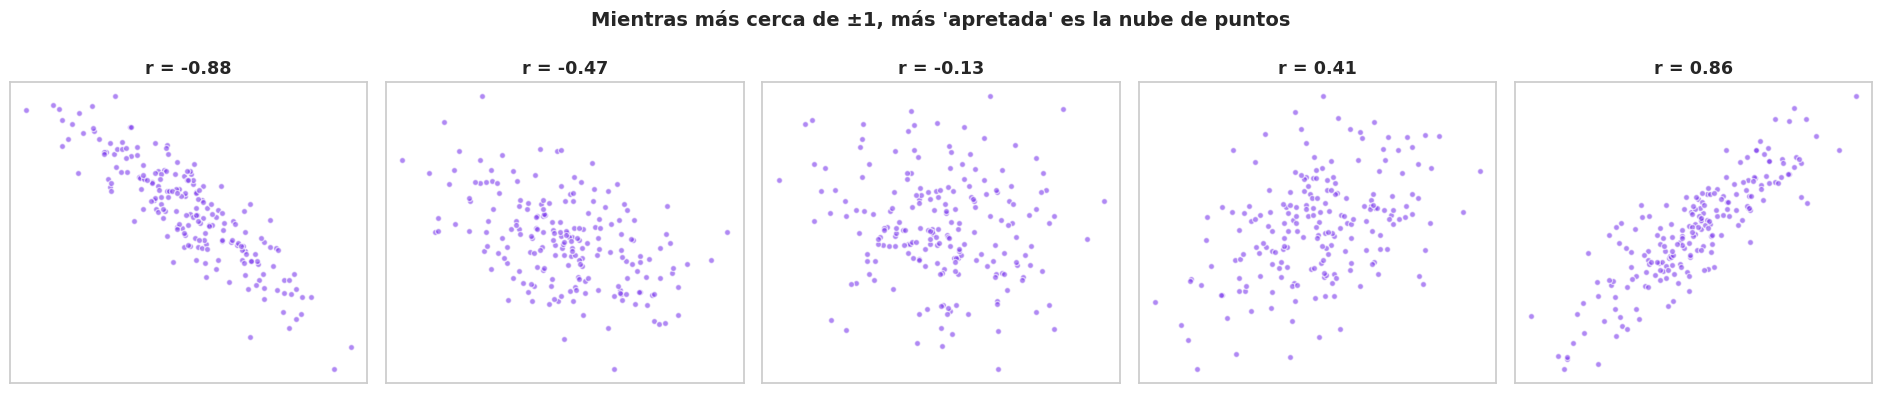

In [ ]:
# 6.1 IMAGEN: ¿CÓMO SE VE CADA VALOR DE r? (DATOS SIMULADOS)
rng = np.random.default_rng(7)
x = rng.normal(0, 1, 200)

fig, axes = plt.subplots(1, 5, figsize=(19, 4))
for ax, r_objetivo in zip(axes, [-0.9, -0.5, 0, 0.5, 0.9]):
    y = r_objetivo * x + np.sqrt(1 - r_objetivo**2) * rng.normal(0, 1, 200)
    r_real = np.corrcoef(x, y)[0, 1]
    ax.scatter(x, y, alpha=0.6, s=18, color="#7c3aed", edgecolor="white")
    ax.set_title(f"r = {r_real:.2f}")
    ax.set_xticks([])
    ax.set_yticks([])
plt.suptitle("Mientras más cerca de ±1, más 'apretada' es la nube de puntos", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [ ]:
# 6.2 PEARSON VS SPEARMAN EN AUTO MPG
variables = ["weight", "displacement", "horsepower", "cylinders"]
comparacion_r = pd.DataFrame({
    "pearson": [df["mpg"].corr(df[v], method="pearson") for v in variables],
    "spearman": [df["mpg"].corr(df[v], method="spearman") for v in variables],
}, index=variables)
comparacion_r["diferencia_|r|"] = comparacion_r["spearman"].abs() - comparacion_r["pearson"].abs()
comparacion_r.round(3)

,pearson,spearman,diferencia_|r|
weight,-0.832,-0.875,0.043
displacement,-0.804,-0.856,0.051
horsepower,-0.778,-0.854,0.075
cylinders,-0.775,-0.822,0.046


**Interpretación:**

- Las cuatro correlaciones son **negativas y fuertes**. La del peso es **r ≈ −0.83**.
- **Spearman sale más fuerte en todas** (peso: −0.87; potencia: −0.85 frente a −0.78 de Pearson). Esto confirma lo que vimos en la Parte 1: la relación es **monótona pero curva**, y Pearson, que busca una recta, la subestima un poco.

## 7. Matriz de correlaciones

La **matriz de correlaciones** calcula r para **todos los pares** de variables a la vez con `df.corr()`:

- Es **simétrica**: r(peso, mpg) = r(mpg, peso).
- La **diagonal vale 1** (cada variable consigo misma).
- Con 7 variables hay **21 pares distintos**.

`origin` **no entra**: es una categórica nominal guardada como número (1, 2, 3), como explicó el grupo 3.

In [ ]:
# 7.1 MATRIZ DE CORRELACIONES (PEARSON)
matriz_corr = df[NUMERICAS].corr()
matriz_corr.round(2)

,mpg,cylinders,displacement,horsepower,weight,acceleration,model_year
mpg,1.00,-0.78,-0.80,-0.78,-0.83,0.42,0.58
cylinders,-0.78,1.00,0.95,0.84,0.90,-0.51,-0.35
displacement,-0.80,0.95,1.00,0.90,0.93,-0.54,-0.37
horsepower,-0.78,0.84,0.90,1.00,0.86,-0.69,-0.42
weight,-0.83,0.90,0.93,0.86,1.00,-0.42,-0.31
acceleration,0.42,-0.51,-0.54,-0.69,-0.42,1.00,0.29
model_year,0.58,-0.35,-0.37,-0.42,-0.31,0.29,1.00


In [ ]:
# 7.2 ¿QUÉ VARIABLES ESTÁN MÁS CORRELACIONADAS CON MPG?
def fuerza(r):
    r = abs(r)
    return "Fuerte" if r >= 0.7 else "Moderada" if r >= 0.3 else "Débil"

corr_mpg = pd.DataFrame({
    "r_pearson": matriz_corr["mpg"].drop("mpg"),
    "r_spearman": df[NUMERICAS].corr(method="spearman")["mpg"].drop("mpg"),
}).sort_values("r_pearson", key=abs, ascending=False)
corr_mpg["direccion"] = np.where(corr_mpg["r_pearson"] < 0, "Negativa", "Positiva")
corr_mpg["fuerza"] = corr_mpg["r_pearson"].apply(fuerza)
corr_mpg.round(3)

,r_pearson,r_spearman,direccion,fuerza
weight,-0.832,-0.875,Negativa,Fuerte
displacement,-0.804,-0.856,Negativa,Fuerte
horsepower,-0.778,-0.854,Negativa,Fuerte
cylinders,-0.775,-0.822,Negativa,Fuerte
model_year,0.579,0.573,Positiva,Moderada
acceleration,0.420,0.439,Positiva,Moderada


**Interpretación (pregunta 2):**

| Puesto | Variable | r | Lectura |
|---|---|---|---|
| 1 | `weight` | −0.83 | Fuerte negativa |
| 2 | `displacement` | −0.80 | Fuerte negativa |
| 3 | `horsepower` | −0.78 | Fuerte negativa |
| 4 | `cylinders` | −0.78 | Fuerte negativa |
| 5 | `model_year` | +0.58 | Moderada positiva: los carros más nuevos rinden más |
| 6 | `acceleration` | +0.42 | Moderada positiva: los que tardan más en acelerar (menos potentes) rinden más |

## 8. Mapas de calor (heatmaps)

Un **heatmap** pinta la matriz con colores para leerla de un vistazo:

- `cmap="RdBu_r"` → **rojo = positiva**, **azul = negativa**, **blanco ≈ 0**.
- `center=0, vmin=-1, vmax=1` → la escala de color es la misma siempre.
- `annot=True` → escribe el valor dentro de cada celda.
- `mask` → oculta el **triángulo superior**: como la matriz es simétrica, esa mitad repite la información.

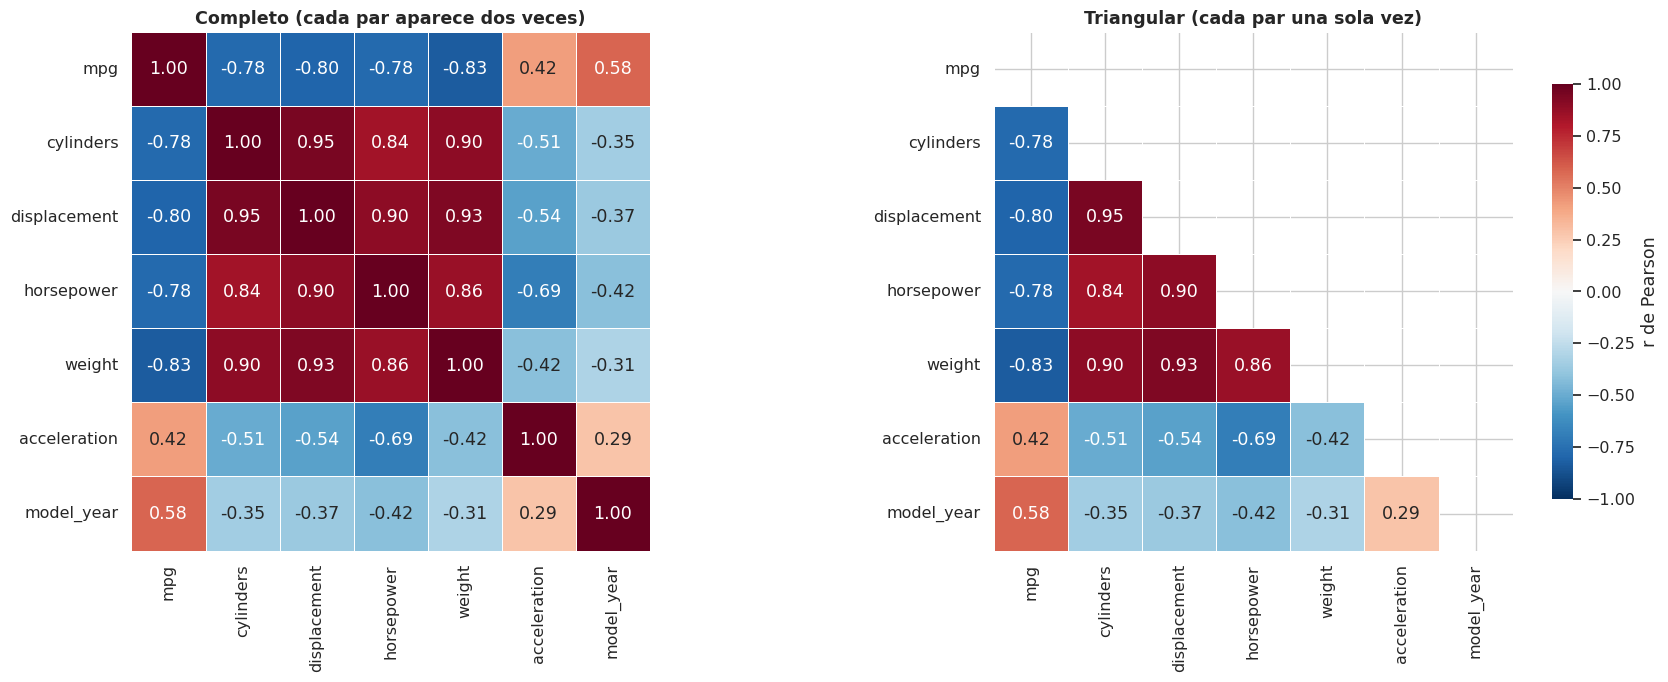

In [ ]:
# 8.1 MAPA DE CALOR: COMPLETO VS TRIANGULAR
mascara = np.triu(np.ones_like(matriz_corr, dtype=bool))   # True = ocultar (triángulo superior + diagonal)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
sns.heatmap(matriz_corr, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar=False, ax=axes[0])
axes[0].set_title("Completo (cada par aparece dos veces)")

sns.heatmap(matriz_corr, mask=mascara, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, linewidths=0.5, cbar_kws={"shrink": 0.8, "label": "r de Pearson"}, ax=axes[1])
axes[1].set_title("Triangular (cada par una sola vez)")
plt.tight_layout()
plt.show()

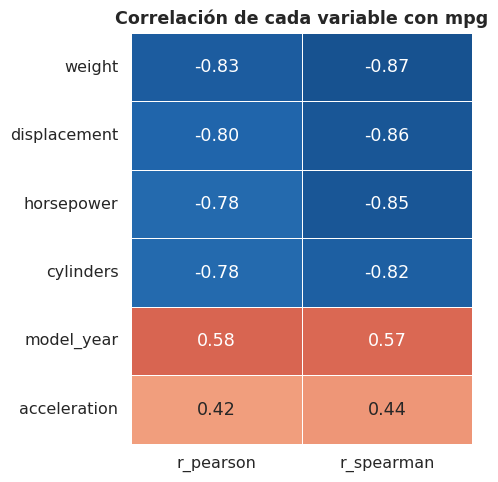

In [ ]:
# 8.2 MAPA DE CALOR ENFOCADO EN MPG
plt.figure(figsize=(5, 5))
sns.heatmap(corr_mpg[["r_pearson", "r_spearman"]], annot=True, fmt=".2f", cmap="RdBu_r",
            center=0, vmin=-1, vmax=1, cbar=False, linewidths=0.5)
plt.title("Correlación de cada variable con mpg")
plt.tight_layout()
plt.show()

**Interpretación:**

- Se ve un **bloque rojo intenso** entre `cylinders`, `displacement`, `horsepower` y `weight` (r entre **0.84 y 0.95**). Estas cuatro variables **miden casi lo mismo**: el tamaño del carro y de su motor.
- La fila de `mpg` es **azul** frente a esas cuatro y **rosada** frente a `model_year` y `acceleration`.

## 9. Identificación automática de correlaciones fuertes

Con 7 variables podemos leer los 21 pares a ojo. Con 30 variables serían **435 pares**. Por eso automatizamos la búsqueda:

1. Nos quedamos con el **triángulo superior**, sin diagonal (`np.triu(..., k=1)`).
2. Convertimos la matriz en una **lista de pares** (`stack`).
3. **Filtramos** los pares con |r| ≥ umbral.
4. **Ordenamos** de mayor a menor |r|.

In [ ]:
# 9.1 FUNCIÓN PARA ENCONTRAR CORRELACIONES FUERTES
def correlaciones_fuertes(datos, umbral=0.7, metodo="pearson"):
    """Devuelve los pares de variables con |r| >= umbral, ordenados de mayor a menor."""
    matriz = datos.corr(method=metodo)
    superior = np.triu(np.ones(matriz.shape, dtype=bool), k=1)   # k=1 excluye la diagonal
    pares = matriz.where(superior).stack().dropna().reset_index()
    pares.columns = ["variable_1", "variable_2", "r"]
    pares = pares[pares["r"].abs() >= umbral].copy()
    pares["direccion"] = np.where(pares["r"] < 0, "Negativa", "Positiva")
    return pares.sort_values("r", key=abs, ascending=False).reset_index(drop=True)

fuertes = correlaciones_fuertes(df[NUMERICAS], umbral=0.7)
n_pares = len(NUMERICAS) * (len(NUMERICAS) - 1) // 2
print(f"PARES REVISADOS: {n_pares} | PARES FUERTES (|r| ≥ 0.7): {len(fuertes)}")
fuertes.round(3)

PARES REVISADOS: 21 | PARES FUERTES (|r| ≥ 0.7): 10


,variable_1,variable_2,r,direccion
0,cylinders,displacement,0.951,Positiva
1,displacement,weight,0.933,Positiva
2,displacement,horsepower,0.897,Positiva
3,cylinders,weight,0.896,Positiva
4,horsepower,weight,0.865,Positiva
5,cylinders,horsepower,0.843,Positiva
6,mpg,weight,-0.832,Negativa
7,mpg,displacement,-0.804,Negativa
8,mpg,horsepower,-0.778,Negativa
9,mpg,cylinders,-0.775,Negativa


In [ ]:
# 9.2 SEPARAR: CORRELACIONES CON MPG VS CORRELACIONES ENTRE PREDICTORAS
con_mpg = fuertes[(fuertes["variable_1"] == "mpg") | (fuertes["variable_2"] == "mpg")]
entre_predictoras = fuertes.drop(con_mpg.index)

print("CORRELACIONES FUERTES CON MPG")
display(con_mpg.round(3))
print("CORRELACIONES FUERTES ENTRE VARIABLES PREDICTORAS (INFORMACIÓN REPETIDA)")
display(entre_predictoras.round(3))

CORRELACIONES FUERTES CON MPG


,variable_1,variable_2,r,direccion
6,mpg,weight,-0.832,Negativa
7,mpg,displacement,-0.804,Negativa
8,mpg,horsepower,-0.778,Negativa
9,mpg,cylinders,-0.775,Negativa


CORRELACIONES FUERTES ENTRE VARIABLES PREDICTORAS (INFORMACIÓN REPETIDA)


,variable_1,variable_2,r,direccion
0,cylinders,displacement,0.951,Positiva
1,displacement,weight,0.933,Positiva
2,displacement,horsepower,0.897,Positiva
3,cylinders,weight,0.896,Positiva
4,horsepower,weight,0.865,Positiva
5,cylinders,horsepower,0.843,Positiva


**Interpretación:**

- De los 21 pares, **10 son fuertes**: **4 con `mpg`** y **6 entre las variables del motor**.
- La más alta de todas es `cylinders`–`displacement` (**r ≈ 0.95**): conociendo una, casi sabemos la otra. A esto se le llama **redundancia** (o *multicolinealidad*): son variables que **repiten información**.

## 10. Relaciones entre variables categóricas

La correlación de Pearson necesita números. Con **categorías** no se calcula r: se **cuenta cuántos casos caen en cada combinación**.

Variables categóricas que usaremos:

| Variable | Tipo | Cómo se obtiene |
|---|---|---|
| `origen` | Nominal | Ya la tenemos (USA, Europa, Japón) |
| `cylinders` | Discreta con pocos valores → se trata como categoría | Ya la tenemos (3, 4, 5, 6, 8) |
| `eficiencia` | Ordinal | Agrupando `mpg`: Baja (≤ 18), Media (18–25), Alta (> 25) |
| `epoca` | Ordinal | Agrupando `model_year` alrededor de la crisis del petróleo de 1973 |

In [ ]:
# 10.1 VARIABLES CATEGÓRICAS PARA EL ANÁLISIS
df["eficiencia"] = pd.cut(df["mpg"], bins=[0, 18, 25, 50], labels=["Baja", "Media", "Alta"])
df["epoca"] = pd.cut(df["model_year"], bins=[69, 73, 77, 82], labels=["1970-73", "1974-77", "1978-82"])

for col in ["origen", "cylinders", "eficiencia", "epoca"]:
    print(f"{col.upper()}:")
    print(df[col].value_counts().sort_index().to_string(), "\n")

ORIGEN:
origen
USA       249
Europa     70
Japón      79 

CYLINDERS:
cylinders
3      4
4    204
5      3
6     84
8    103 

EFICIENCIA:
eficiencia
Baja     124
Media    116
Alta     158 

EPOCA:
epoca
1970-73    125
1974-77    119
1978-82    154 



## 11. Tablas cruzadas con `crosstab`

`pd.crosstab` cuenta **cuántos carros hay en cada combinación** de dos categorías. Es como un `GROUP BY a, b` con `COUNT(*)` en SQL, pero presentado como tabla.

```python
pd.crosstab(filas, columnas, margins=True, normalize=...)
```

- `margins=True` → agrega los **totales** por fila y por columna.
- `normalize` → convierte los conteos en **proporciones** (sección 12).

In [ ]:
# 11.1 TABLA CRUZADA: ORIGEN × CILINDROS
tabla_cil = pd.crosstab(df["origen"], df["cylinders"], margins=True, margins_name="Total")
tabla_cil

cylinders,3,4,5,6,8,Total
origen,,,,,,
USA,0,72,0,74,103,249
Europa,0,63,3,4,0,70
Japón,4,69,0,6,0,79
Total,4,204,3,84,103,398


**Interpretación:**

- Los **103 carros de 8 cilindros son todos de USA**.
- Los de **3 cilindros** son solo japoneses (los Mazda RX de motor rotativo) y los de **5 cilindros**, solo europeos (Audi y Mercedes).
- Europa y Japón son casi todo **4 cilindros**.

In [ ]:
# 11.2 TABLA CRUZADA: ORIGEN × EFICIENCIA
tabla_ef = pd.crosstab(df["origen"], df["eficiencia"], margins=True, margins_name="Total")
tabla_ef

eficiencia,Baja,Media,Alta,Total
origen,,,,
USA,119,76,54,249
Europa,4,22,44,70
Japón,1,18,60,79
Total,124,116,158,398


**Interpretación:** de los **124 carros de eficiencia baja, 119 son de USA**. Pero ojo: USA también tiene más carros en total (249 de 398). Para comparar grupos de **tamaños distintos** necesitamos **porcentajes**.

## 12. Frecuencias y porcentajes

- **Frecuencia absoluta:** cuántos carros (conteo).
- **Frecuencia relativa:** qué proporción (%).

Con `normalize` se elige **sobre qué total** se calcula el porcentaje, y **la pregunta decide cuál usar**:

| `normalize=` | Divide entre | Responde preguntas como |
|---|---|---|
| `"index"` | El total de **cada fila** | De los carros japoneses, ¿qué % es de eficiencia alta? |
| `"columns"` | El total de **cada columna** | De los carros de eficiencia alta, ¿qué % es japonés? |
| `"all"` | El **total general** (398) | ¿Qué % de todos los carros es japonés y de eficiencia alta? |

In [ ]:
# 12.1 LOS TRES TIPOS DE PORCENTAJE
pct_fila = (pd.crosstab(df["origen"], df["eficiencia"], normalize="index") * 100).round(1)
pct_columna = (pd.crosstab(df["origen"], df["eficiencia"], normalize="columns") * 100).round(1)
pct_total = (pd.crosstab(df["origen"], df["eficiencia"], normalize="all") * 100).round(1)

print("% POR FILA (CADA ORIGEN SUMA 100 %)")
display(pct_fila)
print("% POR COLUMNA (CADA NIVEL DE EFICIENCIA SUMA 100 %)")
display(pct_columna)
print("% DEL TOTAL (TODA LA TABLA SUMA 100 %)")
display(pct_total)

% POR FILA (CADA ORIGEN SUMA 100 %)


eficiencia,Baja,Media,Alta
origen,,,
USA,47.8,30.5,21.7
Europa,5.7,31.4,62.9
Japón,1.3,22.8,75.9


% POR COLUMNA (CADA NIVEL DE EFICIENCIA SUMA 100 %)


eficiencia,Baja,Media,Alta
origen,,,
USA,96.0,65.5,34.2
Europa,3.2,19.0,27.8
Japón,0.8,15.5,38.0


% DEL TOTAL (TODA LA TABLA SUMA 100 %)


eficiencia,Baja,Media,Alta
origen,,,
USA,29.9,19.1,13.6
Europa,1.0,5.5,11.1
Japón,0.3,4.5,15.1


**Interpretación:**

- **Por fila:** el **75.9 %** de los japoneses y el **62.9 %** de los europeos tienen eficiencia alta, frente a solo el **21.7 %** de los estadounidenses. Casi la mitad de USA (**47.8 %**) es de eficiencia baja.
- **Por columna:** el **96 %** de los carros de eficiencia baja son de USA. Aun así, el **34 %** de los de eficiencia alta también son de USA, porque USA tiene muchos carros.
- Lección: el **mismo cruce** cuenta historias distintas según el porcentaje. Para **comparar orígenes** usamos el **porcentaje por fila**.

In [ ]:
# 12.2 FRECUENCIA Y PORCENTAJE EN UNA SOLA TABLA (ORIGEN × CILINDROS)
conteo = pd.crosstab(df["origen"], df["cylinders"])
porcentaje = pd.crosstab(df["origen"], df["cylinders"], normalize="index") * 100
conteo.astype(str) + " (" + porcentaje.round(1).astype(str) + " %)"

cylinders,3,4,5,6,8
origen,,,,,
USA,0 (0.0 %),72 (28.9 %),0 (0.0 %),74 (29.7 %),103 (41.4 %)
Europa,0 (0.0 %),63 (90.0 %),3 (4.3 %),4 (5.7 %),0 (0.0 %)
Japón,4 (5.1 %),69 (87.3 %),0 (0.0 %),6 (7.6 %),0 (0.0 %)


<div style="background:#b45309; color:white; padding:18px; border-radius:10px;">
<h1 style="color:white; margin:0;">PARTE 3 — Atípicos, grupos y hallazgos</h1>
<p style="color:#fef3c7; margin:6px 0 0 0;">Gráficas de tablas cruzadas · Atípicos · Boxplot e IQR · Grupos · barplot y pairplot · Hallazgos</p>
</div>

## 13. Visualización de tablas cruzadas

Hay tres formas comunes de graficar una tabla cruzada:

| Gráfica | Muestra | Sirve para |
|---|---|---|
| **Heatmap de conteos** | La tabla con colores | Ver dónde se concentran los datos |
| **Barras agrupadas** | Conteos lado a lado | Comparar cantidades absolutas |
| **Barras apiladas al 100 %** | Porcentaje por fila | Comparar **proporciones** entre grupos de distinto tamaño |

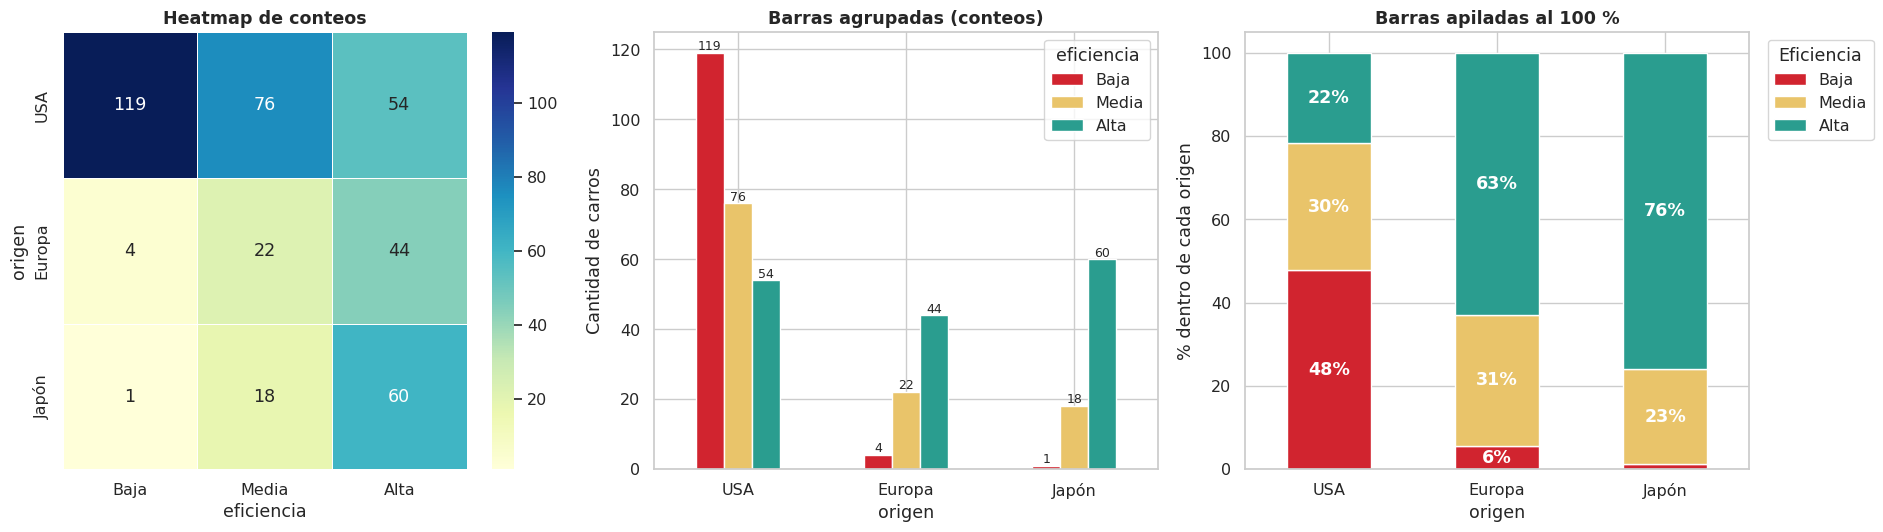

In [ ]:
# 13.1 TRES FORMAS DE GRAFICAR LA TABLA ORIGEN × EFICIENCIA
conteo_ef = pd.crosstab(df["origen"], df["eficiencia"])
colores_ef = ["#d1242f", "#e9c46a", "#2a9d8f"]          # Baja, Media, Alta

fig, axes = plt.subplots(1, 3, figsize=(19, 5.5))

sns.heatmap(conteo_ef, annot=True, fmt="d", cmap="YlGnBu", linewidths=0.5, ax=axes[0])
axes[0].set_title("Heatmap de conteos")

conteo_ef.plot(kind="bar", color=colores_ef, ax=axes[1], rot=0)
axes[1].set_title("Barras agrupadas (conteos)")
axes[1].set_ylabel("Cantidad de carros")
for barras in axes[1].containers:
    axes[1].bar_label(barras, fontsize=9)

pct_fila.plot(kind="bar", stacked=True, color=colores_ef, ax=axes[2], rot=0)
axes[2].set_title("Barras apiladas al 100 %")
axes[2].set_ylabel("% dentro de cada origen")
for barras in axes[2].containers:
    axes[2].bar_label(barras, labels=[f"{v:.0f}%" if v >= 4 else "" for v in barras.datavalues],
                      label_type="center", color="white", fontweight="bold")
axes[2].legend(title="Eficiencia", bbox_to_anchor=(1.02, 1), loc="upper left")

plt.tight_layout()
plt.show()

**Interpretación:**

- En las **barras agrupadas**, USA tiene barras altas en todo porque tiene más carros. Eso **confunde** la comparación.
- Las **barras al 100 %** muestran el patrón real: **3 de cada 4 japoneses** son de eficiencia alta, frente a **1 de cada 5 estadounidenses**.

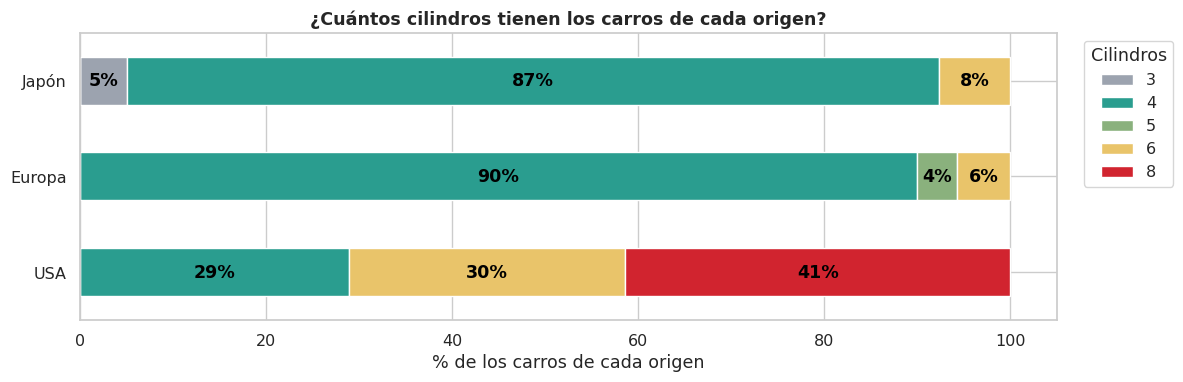

In [ ]:
# 13.2 COMPOSICIÓN DE CILINDROS DENTRO DE CADA ORIGEN
pct_cil = pd.crosstab(df["origen"], df["cylinders"], normalize="index") * 100
colores_cil = ["#9ca3af", "#2a9d8f", "#8ab17d", "#e9c46a", "#d1242f"]   # 3, 4, 5, 6, 8 cilindros

ax = pct_cil.plot(kind="barh", stacked=True, color=colores_cil, figsize=(12, 4))
for barras in ax.containers:
    ax.bar_label(barras, labels=[f"{v:.0f}%" if v >= 4 else "" for v in barras.datavalues],
                 label_type="center", color="black", fontweight="bold")
ax.set_xlabel("% de los carros de cada origen")
ax.set_ylabel("")
ax.set_title("¿Cuántos cilindros tienen los carros de cada origen?")
ax.legend(title="Cilindros", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

**Interpretación:** en USA el **41 %** de los carros tiene 8 cilindros y otro **30 %** tiene 6. En Europa (**90 %**) y Japón (**87 %**) dominan los de 4 cilindros.

## 14. Concepto de valores atípicos

Un **valor atípico (outlier)** es una observación que se aleja mucho del resto de los datos. **Detectarlo no significa eliminarlo**: primero hay que entender de dónde sale.

| Tipo | Ejemplo | Qué hacer |
|---|---|---|
| **Error** | mpg negativo, peso = 0, error de digitación | Corregir o eliminar (y documentarlo) |
| **Real** | Un carro diésel muy eficiente, un deportivo muy potente | **Conservar** y explicar: suele ser lo más interesante |

Además, un dato puede ser:

- **Atípico global:** raro frente a **todos** los carros.
- **Atípico dentro de su grupo:** normal en el total, pero raro frente a los carros de su mismo origen.

Los atípicos importan porque **jalan la media** y afectan la correlación de Pearson.

## 15. Boxplot y regla del rango intercuartílico (IQR)

**Regla del IQR** (propuesta por John Tukey):

- **Q1** = percentil 25 · **Q3** = percentil 75
- **IQR = Q3 − Q1** → el rango donde está el **50 % central** de los datos
- **Límite inferior = Q1 − 1.5 · IQR** · **Límite superior = Q3 + 1.5 · IQR**
- Todo valor **fuera** de esos límites es atípico.

El **boxplot** dibuja exactamente esa regla:

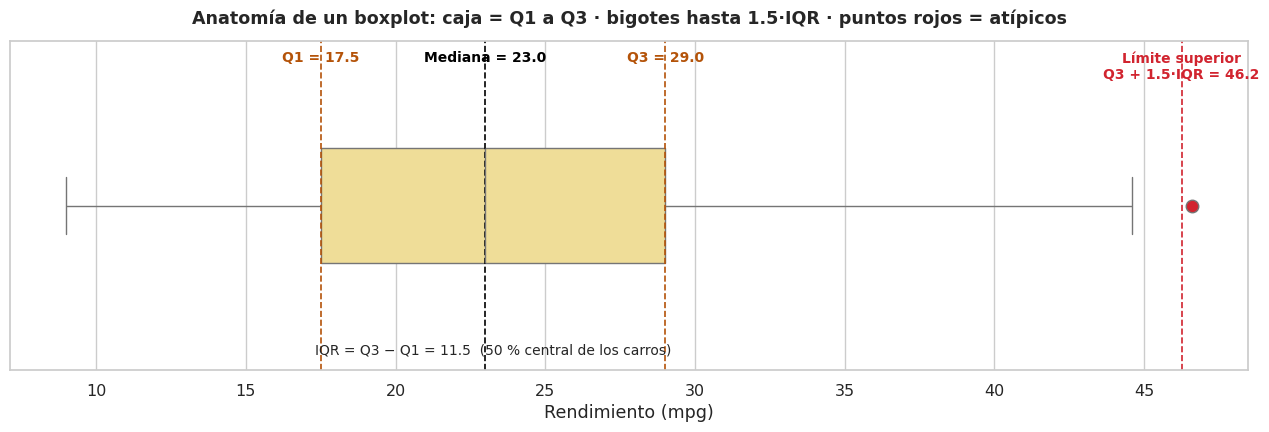

In [ ]:
# 15.1 IMAGEN: CÓMO LEER UN BOXPLOT (EJEMPLO CON MPG)
q1, mediana, q3 = df["mpg"].quantile([0.25, 0.5, 0.75])
iqr = q3 - q1
lim_sup = q3 + 1.5 * iqr

fig, ax = plt.subplots(figsize=(13, 4.5))
sns.boxplot(x=df["mpg"], ax=ax, color="#fde68a", width=0.35,
            flierprops={"markerfacecolor": "#d1242f", "markersize": 9})
etiquetas_box = [
    (q1, f"Q1 = {q1:.1f}", "#b45309"),
    (mediana, f"Mediana = {mediana:.1f}", "black"),
    (q3, f"Q3 = {q3:.1f}", "#b45309"),
    (lim_sup, f"Límite superior\nQ3 + 1.5·IQR = {lim_sup:.1f}", "#d1242f"),
]
for valor, texto, color in etiquetas_box:
    ax.axvline(valor, color=color, ls="--", lw=1.2)
    ax.text(valor, 0.97, texto, transform=ax.get_xaxis_transform(),
            ha="center", va="top", fontsize=10, color=color, fontweight="bold")
ax.text((q1 + q3) / 2, 0.04, f"IQR = Q3 − Q1 = {iqr:.1f}  (50 % central de los carros)",
        transform=ax.get_xaxis_transform(), ha="center", va="bottom", fontsize=10)
ax.set_xlabel(ETIQUETAS["mpg"])
ax.set_title("Anatomía de un boxplot: caja = Q1 a Q3 · bigotes hasta 1.5·IQR · puntos rojos = atípicos", pad=12)
plt.tight_layout()
plt.show()

En `mpg`, el límite superior es **46.25** y solo **un carro** lo supera (el punto rojo). El límite inferior (0.25) está por debajo de cualquier valor posible, así que no hay atípicos por abajo.

In [ ]:
# 15.2 FUNCIONES PARA DETECTAR ATÍPICOS CON LA REGLA DEL IQR
def limites_iqr(serie, k=1.5):
    """Devuelve Q1, Q3, IQR y los límites inferior y superior."""
    q1, q3 = serie.quantile([0.25, 0.75])
    iqr = q3 - q1
    return q1, q3, iqr, q1 - k * iqr, q3 + k * iqr

def es_atipico(serie, k=1.5):
    """True para los valores que quedan fuera de los límites del IQR."""
    _, _, _, lim_inf, lim_sup = limites_iqr(serie, k)
    return (serie < lim_inf) | (serie > lim_sup)

filas = []
for col in NUMERICAS:
    q1, q3, iqr, lim_inf, lim_sup = limites_iqr(df[col])
    n_atip = es_atipico(df[col]).sum()
    filas.append([col, q1, q3, iqr, lim_inf, lim_sup, n_atip, 100 * n_atip / df[col].notna().sum()])

resumen_atipicos = pd.DataFrame(filas, columns=["variable", "Q1", "Q3", "IQR", "lim_inf", "lim_sup",
                                                "n_atipicos", "%_atipicos"])
resumen_atipicos.round(2)

,variable,Q1,Q3,IQR,lim_inf,lim_sup,n_atipicos,%_atipicos
0,mpg,17.50,29.00,11.50,0.25,46.25,1,0.25
1,cylinders,4.00,8.00,4.00,-2.00,14.00,0,0.00
2,displacement,104.25,262.00,157.75,-132.38,498.62,0,0.00
3,horsepower,75.00,126.00,51.00,-1.50,202.50,10,2.55
4,weight,2223.75,3608.00,1384.25,147.38,5684.38,0,0.00
5,acceleration,13.82,17.18,3.35,8.80,22.20,7,1.76
6,model_year,73.00,79.00,6.00,64.00,88.00,0,0.00


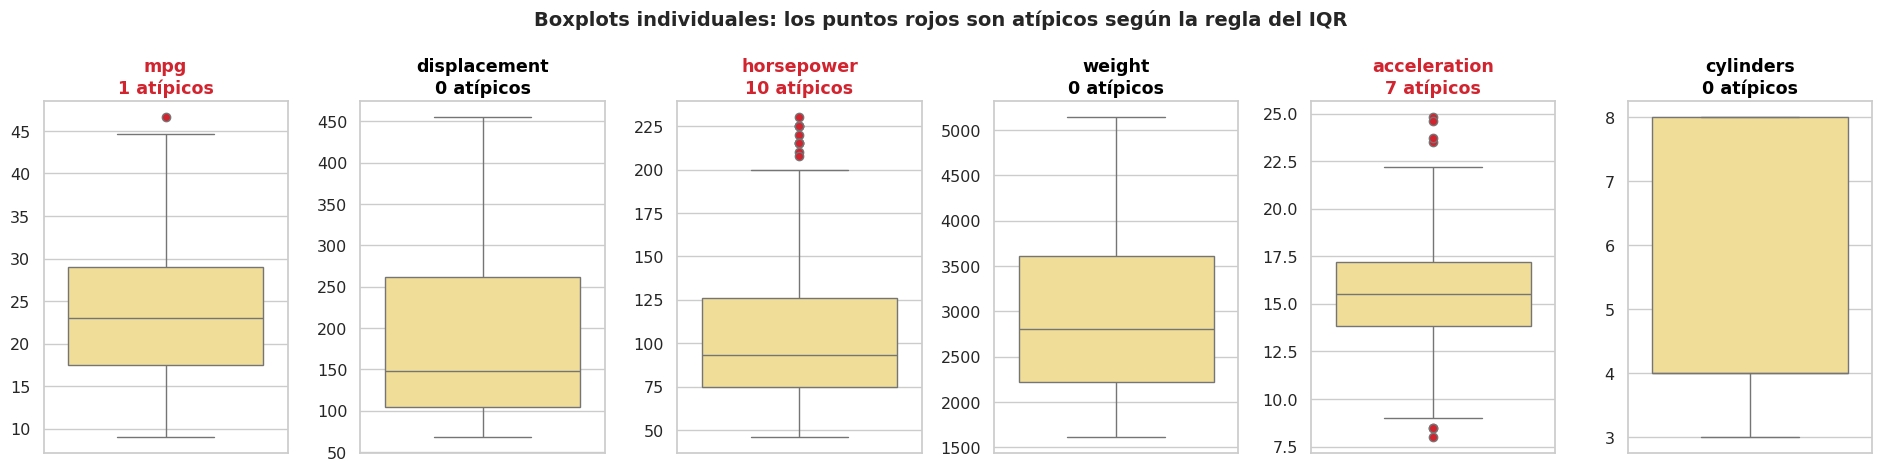

In [ ]:
# 15.3 BOXPLOT DE CADA VARIABLE (CADA UNA CON SU PROPIA ESCALA)
fig, axes = plt.subplots(1, 6, figsize=(19, 4.8))
for ax, col in zip(axes, ["mpg", "displacement", "horsepower", "weight", "acceleration", "cylinders"]):
    sns.boxplot(y=df[col], ax=ax, color="#fde68a", flierprops={"markerfacecolor": "#d1242f"})
    n = es_atipico(df[col]).sum()
    ax.set_title(f"{col}\n{n} atípicos", color="#d1242f" if n else "black")
    ax.set_ylabel("")
plt.suptitle("Boxplots individuales: los puntos rojos son atípicos según la regla del IQR",
             fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()

In [ ]:
# 15.4 ¿QUIÉNES SON LOS CARROS ATÍPICOS?
columnas_ver = ["car_name", "origen", "model_year", "mpg", "horsepower", "weight", "acceleration"]
for col in ["mpg", "horsepower", "acceleration"]:
    print(f"ATÍPICOS EN {col.upper()}:")
    display(df.loc[es_atipico(df[col]), columnas_ver].sort_values(col, ascending=False))

ATÍPICOS EN MPG:


,car_name,origen,model_year,mpg,horsepower,weight,acceleration
322,mazda glc,Japón,80,46.6,65.0,2110,17.9


ATÍPICOS EN HORSEPOWER:


,car_name,origen,model_year,mpg,horsepower,weight,acceleration
116,pontiac grand prix,USA,73,16.0,230.0,4278,9.5
8,pontiac catalina,USA,70,14.0,225.0,4425,10.0
95,buick electra 225 custom,USA,73,12.0,225.0,4951,11.0
13,buick estate wagon (sw),USA,70,14.0,225.0,3086,10.0
6,chevrolet impala,USA,70,14.0,220.0,4354,9.0
7,plymouth fury iii,USA,70,14.0,215.0,4312,8.5
94,chrysler new yorker brougham,USA,73,13.0,215.0,4735,11.0
25,ford f250,USA,70,10.0,215.0,4615,14.0
27,dodge d200,USA,70,11.0,210.0,4382,13.5
67,mercury marquis,USA,72,11.0,208.0,4633,11.0


ATÍPICOS EN ACCELERATION:


,car_name,origen,model_year,mpg,horsepower,weight,acceleration
299,peugeot 504,Europa,79,27.2,71.0,3190,24.8
394,vw pickup,Europa,82,44.0,52.0,2130,24.6
326,vw dasher (diesel),Europa,80,43.4,48.0,2335,23.7
59,volkswagen type 3,Europa,72,23.0,54.0,2254,23.5
7,plymouth fury iii,USA,70,14.0,215.0,4312,8.5
9,amc ambassador dpl,USA,70,15.0,190.0,3850,8.5
11,plymouth 'cuda 340,USA,70,14.0,160.0,3609,8.0


**Interpretación (pregunta 3):**

- **mpg:** un solo atípico, el **Mazda GLC de 1980 (46.6 mpg)**, un carro japonés pequeño y liviano. Es real.
- **horsepower:** **10 atípicos**, todos de **USA entre 1970 y 1973** (Impala, Catalina, Electra, Grand Prix…), con motores V8 de 208 a 230 hp, de antes de la crisis del petróleo. Son reales.
- **acceleration:** carros **muy rápidos** de USA (8–8.5 s) y **muy lentos** de Europa (diésel y pequeños, más de 23 s). Son reales.
- **weight, displacement y cylinders:** ningún atípico.
- **Decisión:** **ningún atípico es un error**, así que **no se elimina ninguno**.

## 16. Patrones relevantes por grupos

Comparar grupos es más que comparar promedios:

1. **Resumir** cada grupo (media, mediana, dispersión).
2. Ver **toda la distribución** con boxplots, no solo el promedio.
3. Buscar **atípicos dentro de cada grupo**.
4. Preguntarse si la diferencia entre grupos se debe a **otra variable** que también cambia entre ellos.

In [ ]:
# 16.1 RESUMEN DE MPG POR ORIGEN
por_origen = df.groupby("origen", observed=True).agg(
    carros=("mpg", "size"),
    mpg_media=("mpg", "mean"),
    mpg_mediana=("mpg", "median"),
    mpg_desv=("mpg", "std"),
    peso_medio=("weight", "mean"),
    potencia_media=("horsepower", "mean"),
)
por_origen.round(1)

,carros,mpg_media,mpg_mediana,mpg_desv,peso_medio,potencia_media
origen,,,,,,
USA,249,20.1,18.5,6.4,3361.9,119.0
Europa,70,27.9,26.5,6.7,2423.3,80.6
Japón,79,30.5,31.6,6.1,2221.2,79.8


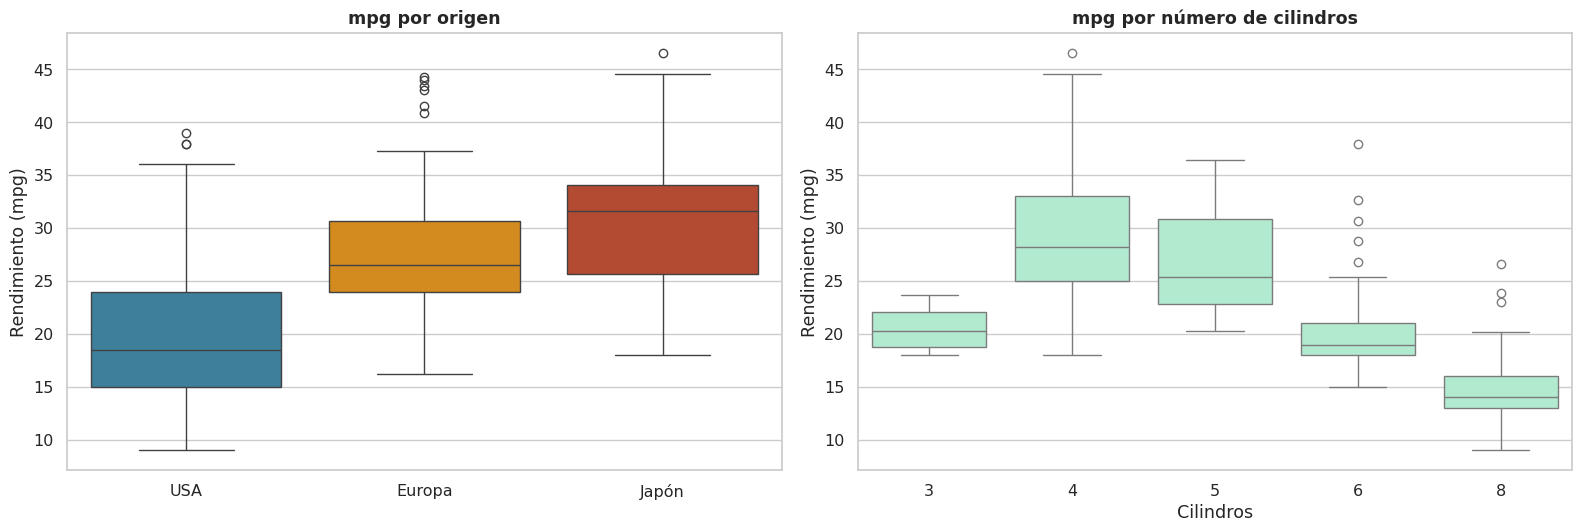

In [ ]:
# 16.2 BOXPLOT DE MPG POR GRUPOS: ORIGEN Y CILINDROS
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

sns.boxplot(data=df, x="origen", y="mpg", hue="origen", palette=PALETA_ORIGEN, legend=False, ax=axes[0])
axes[0].set_title("mpg por origen")
axes[0].set_xlabel("")
axes[0].set_ylabel(ETIQUETAS["mpg"])

sns.boxplot(data=df, x="cylinders", y="mpg", color="#a7f3d0", ax=axes[1])
axes[1].set_title("mpg por número de cilindros")
axes[1].set_xlabel(ETIQUETAS["cylinders"])
axes[1].set_ylabel(ETIQUETAS["mpg"])

plt.tight_layout()
plt.show()

**Interpretación:**

- **Origen:** la mediana es de **31.6 mpg en Japón**, **26.5 en Europa** y **18.5 en USA**. La caja de USA está claramente más abajo y es más ancha.
- **Cilindros:** los de 4 cilindros rinden **≈ 29 mpg** en promedio, los de 6 **≈ 20** y los de 8 **≈ 15**.
- Cuidado con los grupos de 3 y 5 cilindros: tienen solo **4 y 3 carros**, muy pocos para sacar conclusiones.
- Arriba de USA aparecen **puntos sueltos** (38–39 mpg) que en el total serían normales, pero que dentro de USA son atípicos.

In [ ]:
# 16.3 ATÍPICOS DENTRO DE CADA ORIGEN
df["atipico_mpg_global"] = es_atipico(df["mpg"])
df["atipico_mpg_en_origen"] = df.groupby("origen", observed=True)["mpg"].transform(es_atipico).astype(bool)

print("ATÍPICOS GLOBALES EN MPG:", df["atipico_mpg_global"].sum())
print("ATÍPICOS DE MPG DENTRO DE SU ORIGEN:", df["atipico_mpg_en_origen"].sum())
(df.loc[df["atipico_mpg_en_origen"], ["car_name", "origen", "mpg", "weight", "atipico_mpg_global"]]
   .sort_values(["origen", "mpg"], ascending=[True, False]))

ATÍPICOS GLOBALES EN MPG: 1
ATÍPICOS DE MPG DENTRO DE SU ORIGEN: 10


,car_name,origen,mpg,weight,atipico_mpg_global
344,plymouth champ,USA,39.0,1875,False
378,plymouth horizon miser,USA,38.0,2125,False
387,oldsmobile cutlass ciera (diesel),USA,38.0,3015,False
325,vw rabbit c (diesel),Europa,44.3,2085,False
394,vw pickup,Europa,44.0,2130,False
326,vw dasher (diesel),Europa,43.4,2335,False
244,volkswagen rabbit custom diesel,Europa,43.1,1985,False
309,vw rabbit,Europa,41.5,2144,False
330,renault lecar deluxe,Europa,40.9,1835,False
322,mazda glc,Japón,46.6,2110,True


**Interpretación:** en el total hay **1** atípico, pero **dentro de su origen hay 10** (3 de USA, 6 de Europa y 1 de Japón). Por ejemplo, el Plymouth Champ (39 mpg) es normal frente a todos los carros, pero raro para un carro estadounidense. **4 de esos 10 llevan la palabra "diesel" en el nombre**: el tipo de combustible explica parte de lo "raro".

In [ ]:
# 16.4 ¿LA DIFERENCIA POR ORIGEN SE DEBE AL PESO? COMPARAR CARROS DE PESO PARECIDO
df["clase_peso"] = pd.qcut(df["weight"], q=3, labels=["Liviano", "Medio", "Pesado"])

print("CARROS POR CLASE DE PESO Y ORIGEN")
display(pd.crosstab(df["clase_peso"], df["origen"]))

mpg_origen_peso = df.pivot_table(index="clase_peso", columns="origen", values="mpg",
                                 aggfunc="mean", observed=True).round(1)
print("MPG PROMEDIO POR CLASE DE PESO Y ORIGEN (NaN = NO HAY CARROS EN ESA COMBINACIÓN)")
display(mpg_origen_peso)

brecha_total = por_origen.loc["Japón", "mpg_media"] - por_origen.loc["USA", "mpg_media"]
brecha_liviano = mpg_origen_peso.loc["Liviano", "Japón"] - mpg_origen_peso.loc["Liviano", "USA"]
print(f"BRECHA JAPÓN – USA EN EL TOTAL:            {brecha_total:.1f} mpg")
print(f"BRECHA JAPÓN – USA ENTRE CARROS LIVIANOS:   {brecha_liviano:.1f} mpg")

CARROS POR CLASE DE PESO Y ORIGEN


origen,USA,Europa,Japón
clase_peso,,,
Liviano,34,42,58
Medio,85,25,21
Pesado,130,3,0


MPG PROMEDIO POR CLASE DE PESO Y ORIGEN (NaN = NO HAY CARROS EN ESA COMBINACIÓN)


origen,USA,Europa,Japón
clase_peso,,,
Liviano,30.0,30.8,32.0
Medio,22.8,24.0,26.2
Pesado,15.7,19.4,NaN


BRECHA JAPÓN – USA EN EL TOTAL:            10.4 mpg
BRECHA JAPÓN – USA ENTRE CARROS LIVIANOS:   2.0 mpg


**Interpretación (el patrón más importante del análisis):**

- En la clase **"Pesado" hay 130 carros de USA, 3 de Europa y ninguno de Japón**.
- Si comparamos **todos** los carros, Japón rinde **≈ 10.4 mpg más** que USA. Si comparamos solo carros **livianos**, la diferencia baja a **≈ 2 mpg** (32.0 frente a 30.0).
- Conclusión: **la mayor parte de la ventaja de Japón y Europa se explica porque fabrican carros más livianos**, no solo por "ser" de otro origen. Aun así, dentro de cada clase de peso Japón sigue un poco arriba.

## 17. `barplot` y `pairplot`

**`sns.barplot`**

- La altura de la barra es el **promedio** del grupo.
- La línea negra es la **barra de error**: por defecto, el **intervalo de confianza del 95 %**, el rango donde probablemente está el promedio real. Si los intervalos de dos grupos no se tocan, la diferencia es clara.
- Esconde la distribución, por eso conviene acompañarlo de un boxplot.

**`sns.pairplot`**

- Es una **matriz de gráficas**: en la diagonal la distribución de cada variable y fuera de ella la dispersión de **cada par**.
- `hue` colorea por grupo y `corner=True` quita la mitad repetida.
- Con muchas variables se vuelve pesado (n² gráficas).

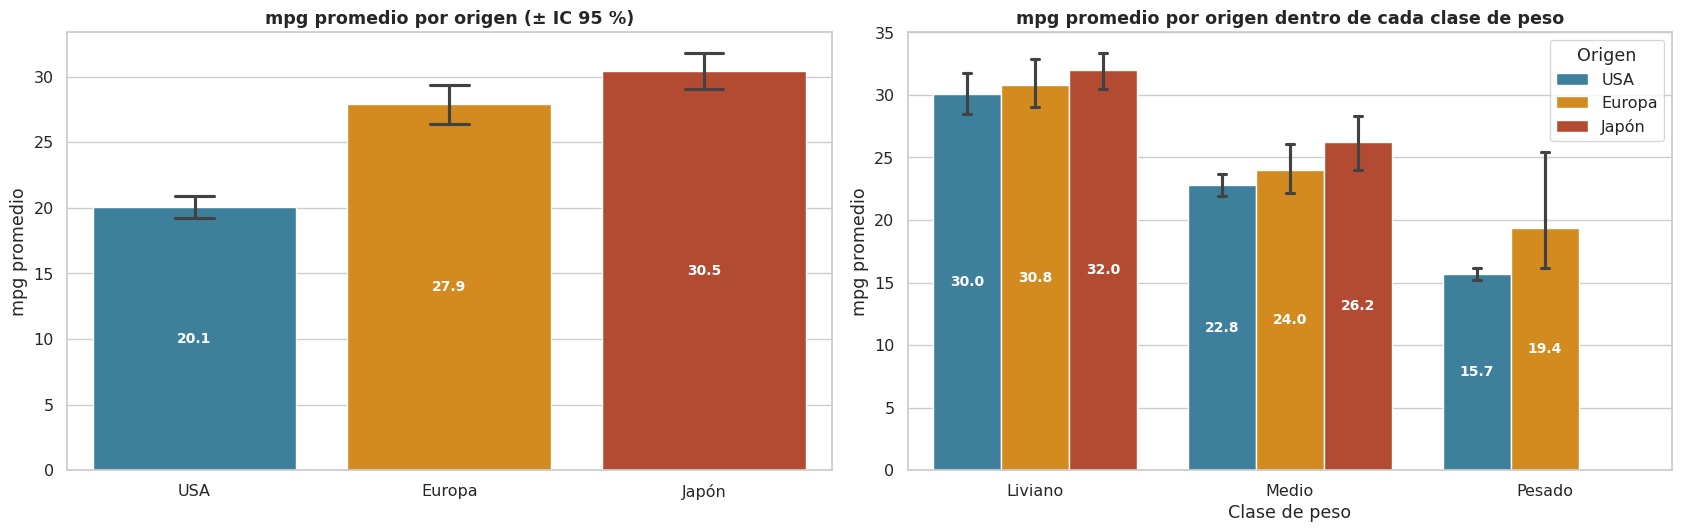

In [ ]:
# 17.1 BARPLOT: MPG PROMEDIO POR ORIGEN, EN TOTAL Y DENTRO DE CADA CLASE DE PESO
def etiquetar_barras(ax):
    """Escribe el valor dentro de cada barra (omite las barras sin dato)."""
    for barras in ax.containers:
        ax.bar_label(barras, labels=[f"{v:.1f}" if v == v else "" for v in barras.datavalues],
                     label_type="center", color="white", fontweight="bold", fontsize=10)

fig, axes = plt.subplots(1, 2, figsize=(17, 5.5))

sns.barplot(data=df, x="origen", y="mpg", hue="origen", palette=PALETA_ORIGEN, legend=False,
            errorbar=("ci", 95), capsize=0.15, ax=axes[0])
etiquetar_barras(axes[0])
axes[0].set_title("mpg promedio por origen (± IC 95 %)")
axes[0].set_xlabel("")
axes[0].set_ylabel("mpg promedio")

sns.barplot(data=df, x="clase_peso", y="mpg", hue="origen", palette=PALETA_ORIGEN,
            errorbar=("ci", 95), capsize=0.1, ax=axes[1])
etiquetar_barras(axes[1])
axes[1].set_title("mpg promedio por origen dentro de cada clase de peso")
axes[1].set_xlabel("Clase de peso")
axes[1].set_ylabel("mpg promedio")
axes[1].legend(title="Origen")

plt.tight_layout()
plt.show()

**Interpretación:**

- **Izquierda:** las barras de error de USA no se tocan con las de Europa y Japón, así que la diferencia en el total **es clara**.
- **Derecha:** entre carros de peso parecido, las barras **se acercan mucho**. En "Pesado", Europa tiene solo 3 carros y su barra de error es enorme: con tan pocos datos **no se puede concluir nada**.

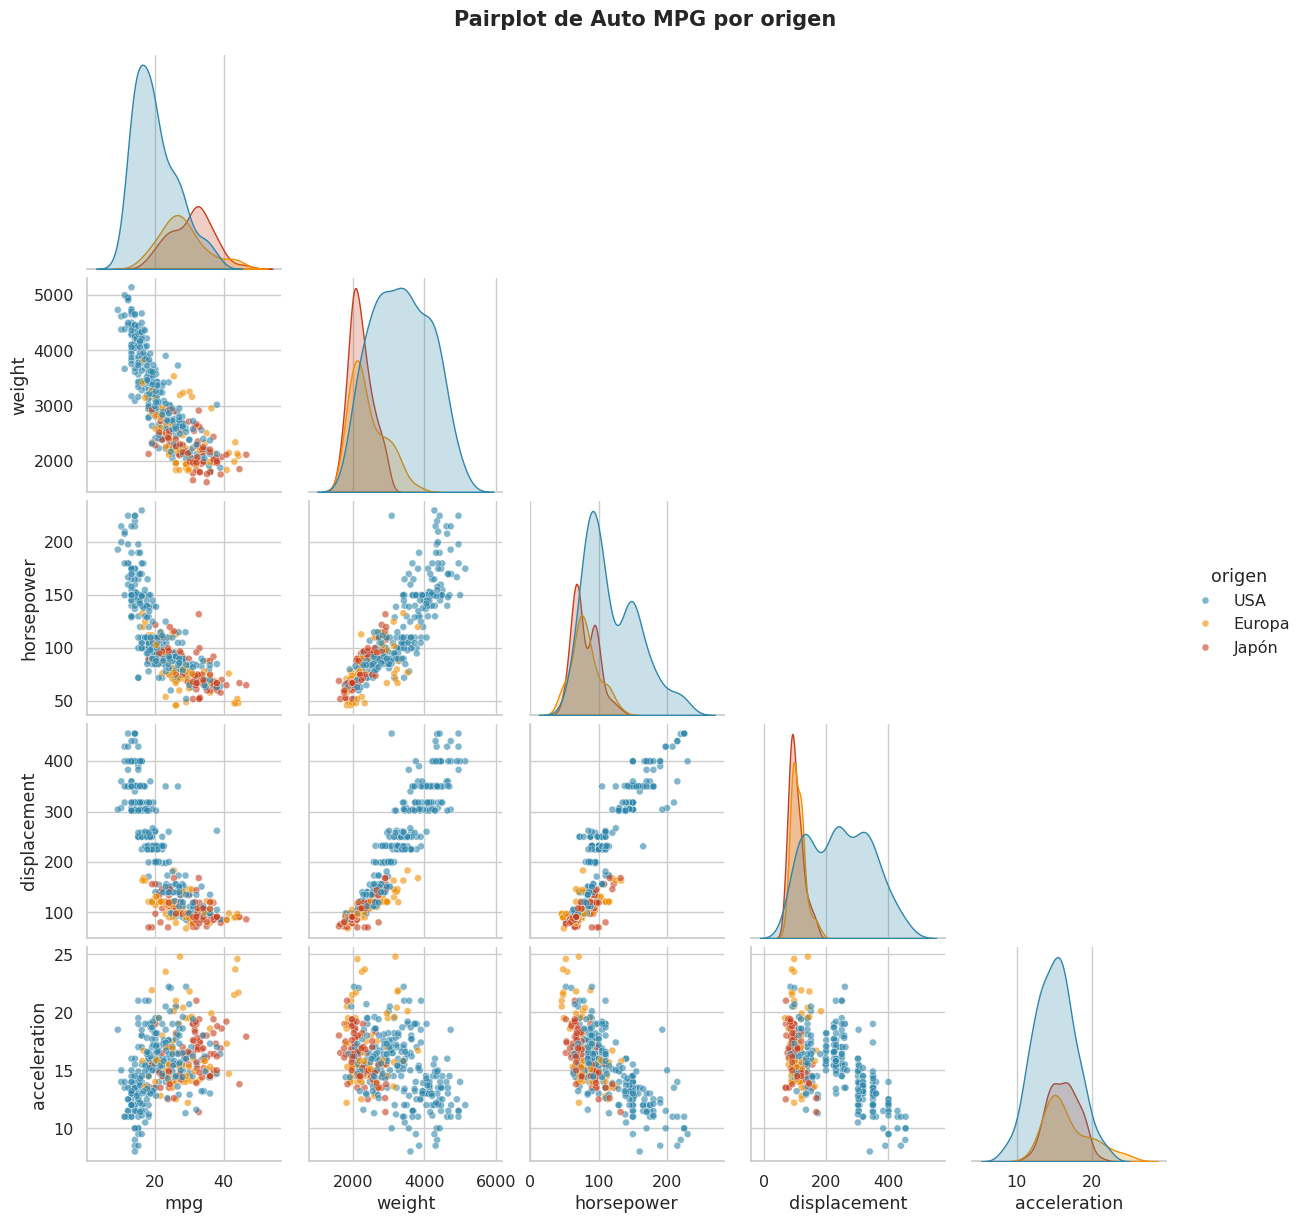

In [ ]:
# 17.2 PAIRPLOT: TODAS LAS RELACIONES DE UNA VEZ, COLOREADAS POR ORIGEN
g = sns.pairplot(df, vars=["mpg", "weight", "horsepower", "displacement", "acceleration"],
                 hue="origen", palette=PALETA_ORIGEN, corner=True, diag_kind="kde",
                 plot_kws={"alpha": 0.6, "s": 25}, height=2.4)
g.figure.suptitle("Pairplot de Auto MPG por origen", y=1.02, fontsize=15, fontweight="bold")
plt.show()

**Interpretación:** en una sola imagen se resume casi todo lo anterior:

- La **columna de `mpg`** muestra curvas descendentes con peso, potencia y cilindrada, y una relación positiva más débil con `acceleration`.
- Entre `weight`, `horsepower` y `displacement` los puntos forman casi **líneas**: la redundancia que encontró la Parte 2.
- Los colores muestran a **Japón y Europa** agrupados en la zona liviana y de poca potencia. En la diagonal, la distribución de mpg de USA está corrida hacia la izquierda.

## 18. Formulación y documentación de hallazgos exploratorios

Un **hallazgo** es una afirmación **corta y verificable** que responde una pregunta y se apoya en un **número** y una **gráfica**.

| ❌ Débil | ✅ Bien formulado |
|---|---|
| "El peso influye en el consumo." | "Los carros de más de 3500 lb rinden en promedio 15.2 mpg, la mitad que los de menos de 2500 lb (30.6 mpg); r = −0.83 (gráficas 3.1 y 5.1)." |
| "Los japoneses son mejores." | "El 76 % de los carros japoneses es de eficiencia alta, frente al 22 % de los de USA (gráfica 13.1)." |

**Lista de chequeo:** ✔ responde una pregunta · ✔ tiene un número · ✔ cita la gráfica que lo muestra · ✔ se puede verificar volviendo a ejecutar el notebook.

**Documentar** es dejar los hallazgos registrados en una tabla, igual que la bitácora de decisiones del tema de limpieza. Los números se calculan con código, **no se copian a mano**.

In [ ]:
# 18.1 BITÁCORA DE HALLAZGOS (LOS NÚMEROS SE CALCULAN, NO SE ESCRIBEN A MANO)
hallazgos = []

def registrar_hallazgo(pregunta, hallazgo, evidencia, grafica):
    hallazgos.append({"pregunta": pregunta, "hallazgo": hallazgo, "evidencia": evidencia, "grafica": grafica})

r_peso = df["mpg"].corr(df["weight"])
mpg_liviano = df.loc[df["weight"] <= 2500, "mpg"].mean()
mpg_pesado = df.loc[df["weight"] > 3500, "mpg"].mean()
registrar_hallazgo(
    "¿Cómo se relacionan peso y MPG?",
    "A mayor peso, menor rendimiento: relación fuerte, negativa y curva.",
    f"r = {r_peso:.2f}; ≤ 2500 lb: {mpg_liviano:.1f} mpg vs > 3500 lb: {mpg_pesado:.1f} mpg",
    "3.1, 4.3, 5.1",
)

texto_top = ", ".join(f"{v} ({r:.2f})" for v, r in corr_mpg["r_pearson"].head(4).items())
r_cil_disp = matriz_corr.loc["cylinders", "displacement"]
registrar_hallazgo(
    "¿Qué variables están más correlacionadas con MPG?",
    "Las cuatro variables del tamaño del motor (fuertes y negativas), que además se repiten entre sí.",
    f"{texto_top}; cylinders–displacement r = {r_cil_disp:.2f}",
    "7.2, 8.1, 9.2",
)

n_atip = {col: int(es_atipico(df[col]).sum()) for col in ["mpg", "horsepower", "acceleration", "weight", "displacement"]}
registrar_hallazgo(
    "¿Existen valores atípicos?",
    "Pocos, y todos son carros reales (no errores): se conservan.",
    ", ".join(f"{k}: {v}" for k, v in n_atip.items()),
    "15.1, 15.3, 15.4, 16.3",
)

registrar_hallazgo(
    "¿Hay diferencias según el origen?",
    "Sí: Japón y Europa rinden más que USA, pero la mayor parte de la brecha se explica por el peso.",
    f"Japón {por_origen.loc['Japón', 'mpg_media']:.1f} / Europa {por_origen.loc['Europa', 'mpg_media']:.1f} / "
    f"USA {por_origen.loc['USA', 'mpg_media']:.1f} mpg; brecha Japón–USA: {brecha_total:.1f} en total "
    f"vs {brecha_liviano:.1f} entre livianos",
    "13.1, 16.2, 16.4, 17.1",
)

bitacora_hallazgos = pd.DataFrame(hallazgos)
bitacora_hallazgos.index = bitacora_hallazgos.index + 1
bitacora_hallazgos.to_csv("hallazgos_auto_mpg.csv", index_label="n")
pd.set_option("display.max_colwidth", None)
bitacora_hallazgos

,pregunta,hallazgo,evidencia,grafica
1,¿Cómo se relacionan peso y MPG?,"A mayor peso, menor rendimiento: relación fuerte, negativa y curva.",r = -0.83; ≤ 2500 lb: 30.6 mpg vs > 3500 lb: 15.2 mpg,"3.1, 4.3, 5.1"
2,¿Qué variables están más correlacionadas con MPG?,"Las cuatro variables del tamaño del motor (fuertes y negativas), que además se repiten entre sí.","weight (-0.83), displacement (-0.80), horsepower (-0.78), cylinders (-0.78); cylinders–displacement r = 0.95","7.2, 8.1, 9.2"
3,¿Existen valores atípicos?,"Pocos, y todos son carros reales (no errores): se conservan.","mpg: 1, horsepower: 10, acceleration: 7, weight: 0, displacement: 0","15.1, 15.3, 15.4, 16.3"
4,¿Hay diferencias según el origen?,"Sí: Japón y Europa rinden más que USA, pero la mayor parte de la brecha se explica por el peso.",Japón 30.5 / Europa 27.9 / USA 20.1 mpg; brecha Japón–USA: 10.4 en total vs 2.0 entre livianos,"13.1, 16.2, 16.4, 17.1"


La bitácora queda guardada en `hallazgos_auto_mpg.csv` (panel de archivos de Colab, a la izquierda).

## 19. Los 3 hallazgos finales del análisis de Auto MPG

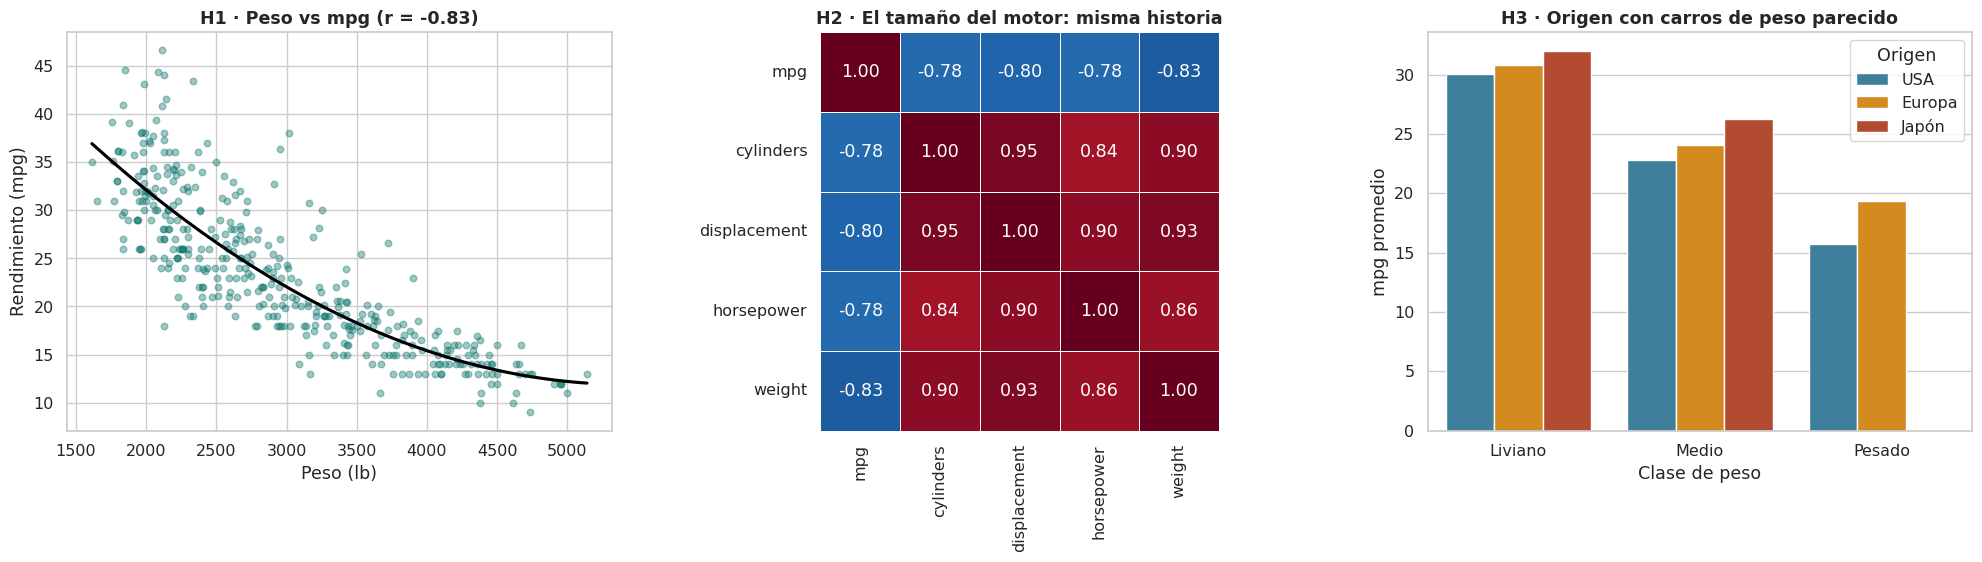

In [ ]:
# 19.1 PANEL DE EVIDENCIA: UNA GRÁFICA POR HALLAZGO
fig, axes = plt.subplots(1, 3, figsize=(20, 5.8))

# Hallazgo 1: peso vs mpg con tendencia curva
sns.regplot(data=df, x="weight", y="mpg", order=2, ci=None, ax=axes[0],
            scatter_kws={"alpha": 0.4, "s": 22, "color": "#0f766e"}, line_kws={"color": "black"})
axes[0].set_title(f"H1 · Peso vs mpg (r = {r_peso:.2f})")
axes[0].set_xlabel(ETIQUETAS["weight"])
axes[0].set_ylabel(ETIQUETAS["mpg"])

# Hallazgo 2: las variables del tamaño del motor
tamano = ["mpg", "cylinders", "displacement", "horsepower", "weight"]
sns.heatmap(df[tamano].corr(), annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1,
            square=True, cbar=False, linewidths=0.5, ax=axes[1])
axes[1].set_title("H2 · El tamaño del motor: misma historia")

# Hallazgo 3: origen comparando carros de peso parecido
sns.barplot(data=df, x="clase_peso", y="mpg", hue="origen", palette=PALETA_ORIGEN, errorbar=None, ax=axes[2])
axes[2].set_title("H3 · Origen con carros de peso parecido")
axes[2].set_xlabel("Clase de peso")
axes[2].set_ylabel("mpg promedio")
axes[2].legend(title="Origen")

plt.tight_layout()
plt.show()

---

**Hallazgo 1: el peso es la variable más asociada al rendimiento, y la relación es curva.**
El peso tiene la correlación más fuerte con mpg (**r = −0.83**; Spearman **−0.87**). Los carros de menos de 2500 lb rinden **30.6 mpg** y los de más de 3500 lb, **15.2 mpg**. Cada 1000 lb adicionales restan ≈ **7.7 mpg**, aunque la caída se aplana en los carros más pesados. *Gráficas 3.1, 5.1 y H1.*

---

**Hallazgo 2: cilindros, cilindrada, potencia y peso cuentan la misma historia.**
Las cuatro tienen correlación fuerte y negativa con mpg (**−0.78 a −0.83**) y entre ellas se correlacionan entre **0.84 y 0.95**. En la práctica miden una sola cosa: **el tamaño del carro y de su motor**. *Gráficas 4.2, 8.1, 9.2 y H2.*

---

**Hallazgo 3: la ventaja de Japón y Europa se explica sobre todo por el peso.**
En promedio, Japón rinde **30.5 mpg**, Europa **27.9** y USA **20.1**, y el **76 %** de los japoneses es de eficiencia alta frente al **22 %** de USA. Pero USA tiene **130 de los 133 carros más pesados** y **todos los de 8 cilindros**. Al comparar carros de peso parecido, la brecha Japón–USA baja de **≈ 10 a ≈ 2 mpg**. *Gráficas 13.1, 16.4, 17.1 y H3.*

---

<div style="background:#1e3a8a; color:white; padding:18px; border-radius:10px;">
<h1 style="color:white; margin:0;">CIERRE — Respuestas del caso Auto MPG</h1>
<p style="color:#dbeafe; margin:6px 0 0 0;">Las responden los tres integrantes</p>
</div>

## 20. Respuesta a las preguntas de Auto MPG

| Pregunta | Respuesta corta | Evidencia | La presenta |
|---|---|---|---|
| **1. ¿Cómo se relacionan peso y MPG?** | Relación **negativa, fuerte y curva**: a más peso, menos mpg (≈ −7.7 mpg por cada 1000 lb) | r = −0.83 · gráficas 3.1, 4.3, 5.1 | Parte 1 |
| **2. ¿Qué variables están más correlacionadas con MPG?** | `weight` (−0.83), `displacement` (−0.80), `horsepower` (−0.78) y `cylinders` (−0.78), que además son redundantes entre sí | Matriz 7.2 · heatmap 8.1 · tabla 9.2 | Parte 2 |
| **3. ¿Existen valores atípicos?** | Pocos: 1 en mpg, 10 en horsepower, unos 7 en acceleration y ninguno en peso ni cilindrada. **Todos son carros reales** y se conservan | Tabla 15.2 · boxplots 15.3 · lista 15.4 | Parte 3 |
| **4. ¿Hay diferencias según el origen?** | Sí: Japón 30.5 > Europa 27.9 > USA 20.1 mpg. Pero con carros de peso parecido la diferencia se reduce mucho | Porcentajes 12.1 · gráfica 13.1 · tabla 16.4 · barplot 17.1 | Partes 2 y 3 |

## 21. Conclusiones

1. **El EDA avanzado mira las variables juntas.** Una variable sola dice *cuánto*; dos o más dicen *por qué*.
2. **La forma de la relación importa.** Como la relación es curva, Spearman sale más fuerte que Pearson: siempre hay que **mirar la gráfica** antes de confiar en un solo número.
3. **Correlaciones fuertes entre predictoras significan información repetida.** Cilindros, cilindrada, potencia y peso miden casi lo mismo.
4. **Con categóricas, la pregunta decide el porcentaje.** Para comparar grupos de distinto tamaño se usa el porcentaje por fila.
5. **Detectar un atípico no es eliminarlo.** En Auto MPG todos los atípicos son carros reales.
6. **Comparar grupos parecidos puede cambiar la conclusión.** La brecha por origen pasa de ≈ 10 a ≈ 2 mpg al comparar carros del mismo peso.

**Para pensar:**

- Si cambian el umbral de `correlaciones_fuertes` a **0.5**, ¿qué pares nuevos aparecen?
- Varios atípicos dentro de su origen son **diésel**. ¿Qué variable creada por el grupo 3 ayudaría a explicarlos?
- ¿Por qué no hay carros japoneses en la clase "Pesado"? ¿Qué implica eso al comparar orígenes?

## Referencias

- Quinlan, R. (1993). *Auto MPG* [Dataset]. UCI Machine Learning Repository.
- Tukey, J. W. (1977). *Exploratory Data Analysis*. Addison-Wesley.
- McKinney, W. (2022). *Python for Data Analysis* (3.ª ed.). O'Reilly.
- Documentación de seaborn: `scatterplot`, `relplot`, `regplot`, `heatmap`, `boxplot`, `barplot`, `pairplot`.
- Documentación de pandas: `DataFrame.corr`, `crosstab`, `cut`, `qcut`, `pivot_table`.

---
<div style="text-align:center; color:#6e7781;">Grupo 4 · Análisis exploratorio avanzado con Matplotlib y Seaborn · Auto MPG</div>